In [1]:
import pandas as pd
train = pd.read_csv("train.csv")
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
# Menampilkan ringkasan informasi dari dataset
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [3]:
# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
count,1460.000000,1460.000000,1460,1201.000000,1460.000000,1460,91,1460,1460,1460,...,1460.000000,7,281,54,1460.000000,1460.000000,1460.000000,1460,1460,1460.000000
unique,NaN,NaN,5,NaN,NaN,2,2,4,4,2,...,NaN,3,4,4,NaN,NaN,NaN,9,6,NaN
top,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,AllPub,...,NaN,Gd,MnPrv,Shed,NaN,NaN,NaN,WD,Normal,NaN
freq,NaN,NaN,1151,NaN,NaN,1454,50,925,1311,1459,...,NaN,3,157,49,NaN,NaN,NaN,1267,1198,NaN
mean,730.500000,56.897260,NaN,70.049958,10516.828082,NaN,NaN,NaN,NaN,NaN,...,2.758904,NaN,NaN,NaN,43.489041,6.321918,2007.815753,NaN,NaN,180921.195890
std,421.610009,42.300571,NaN,24.284752,9981.264932,NaN,NaN,NaN,NaN,NaN,...,40.177307,NaN,NaN,NaN,496.123024,2.703626,1.328095,NaN,NaN,79442.502883
min,1.000000,20.000000,NaN,21.000000,1300.000000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,1.000000,2006.000000,NaN,NaN,34900.000000
25%,365.750000,20.000000,NaN,59.000000,7553.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,5.000000,2007.000000,NaN,NaN,129975.000000
50%,730.500000,50.000000,NaN,69.000000,9478.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,6.000000,2008.000000,NaN,NaN,163000.000000
75%,1095.250000,70.000000,NaN,80.000000,11601.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,8.000000,2009.000000,NaN,NaN,214000.000000


In [4]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

In [5]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [6]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [7]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['str']).columns
 
for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

In [8]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

In [9]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

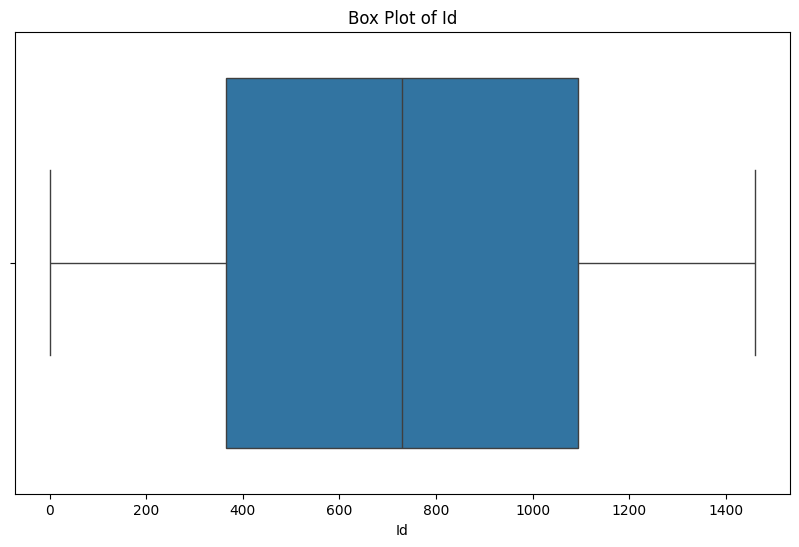

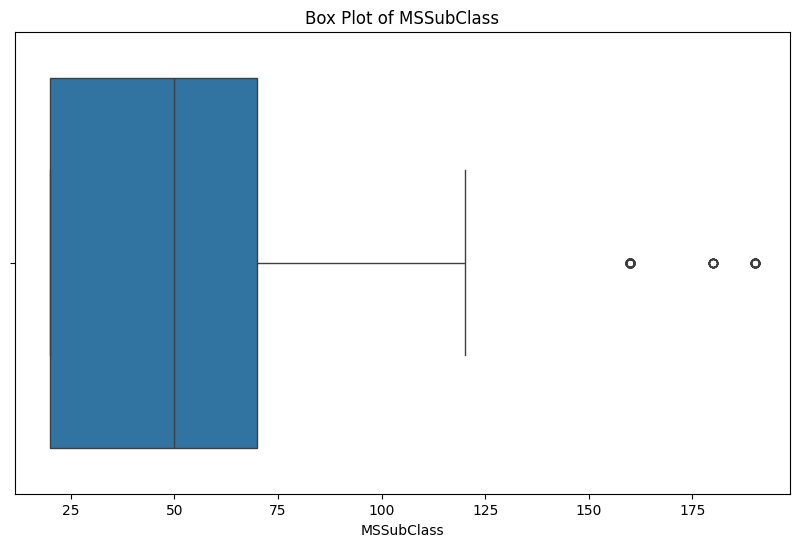

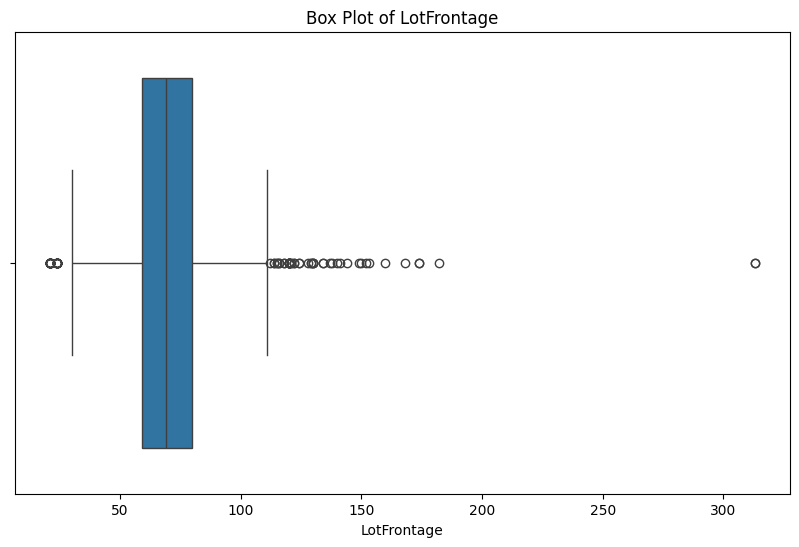

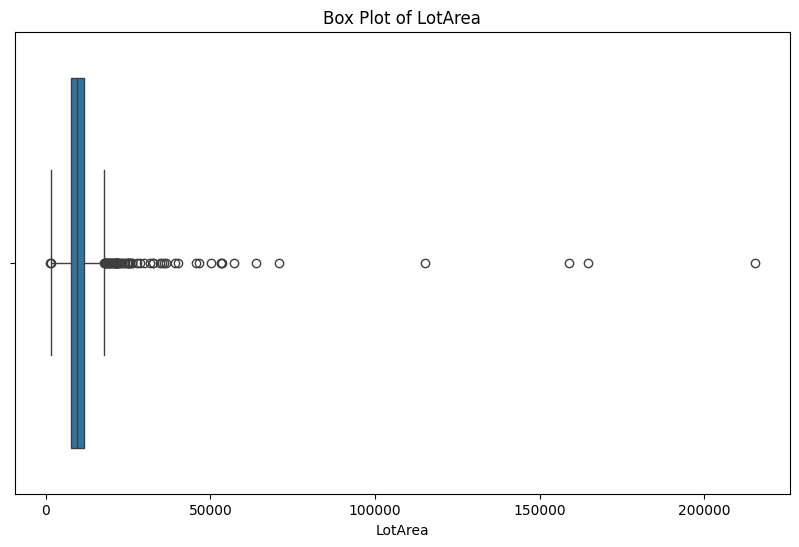

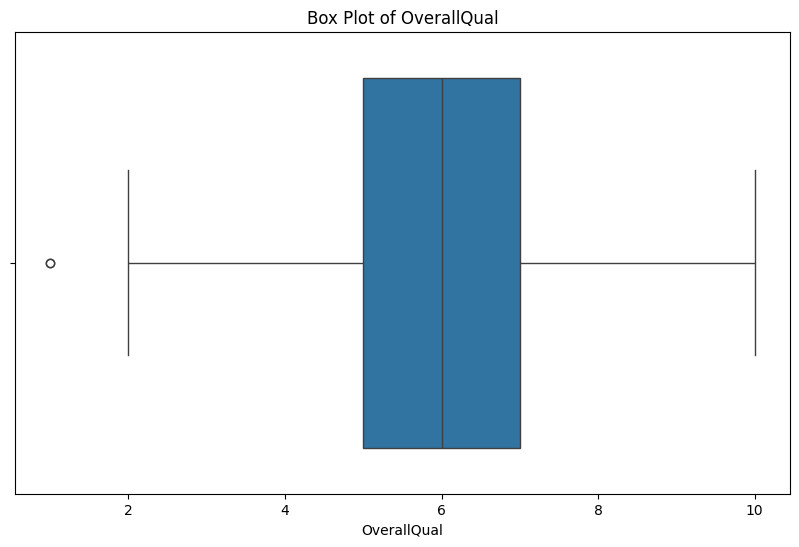

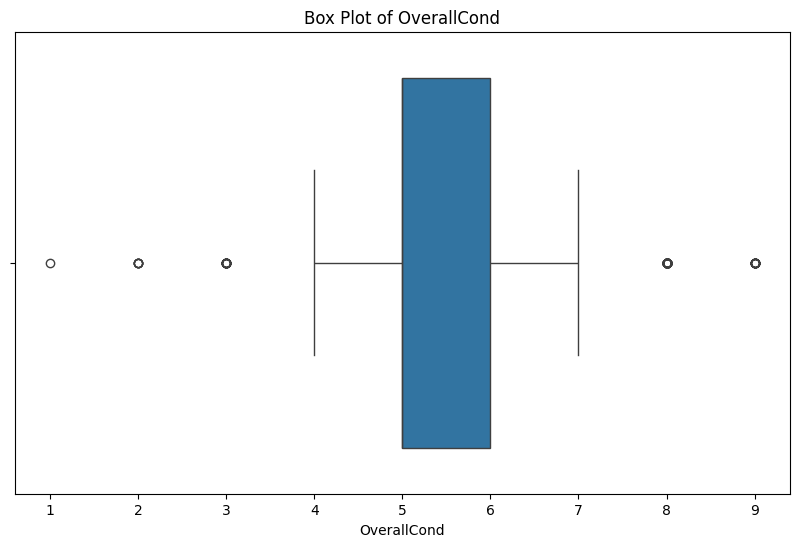

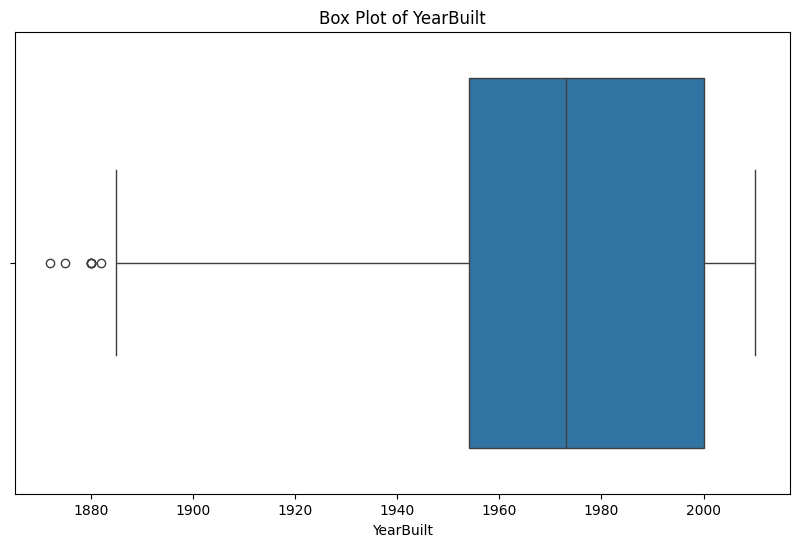

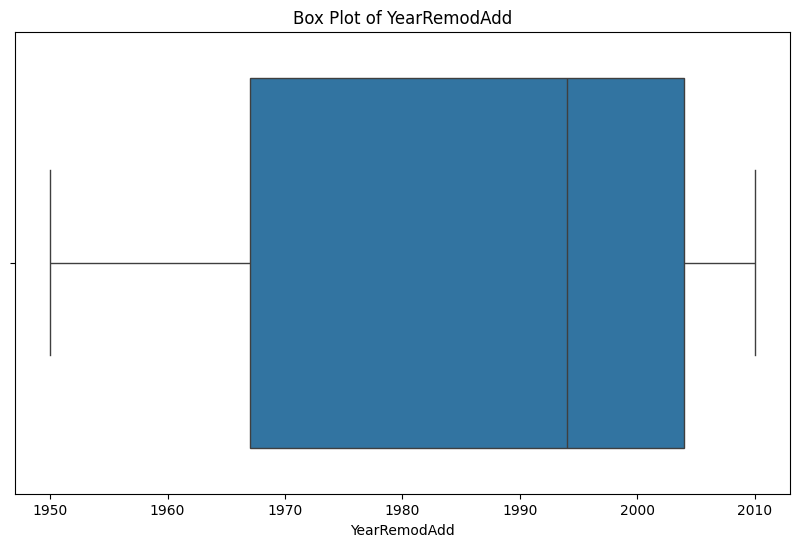

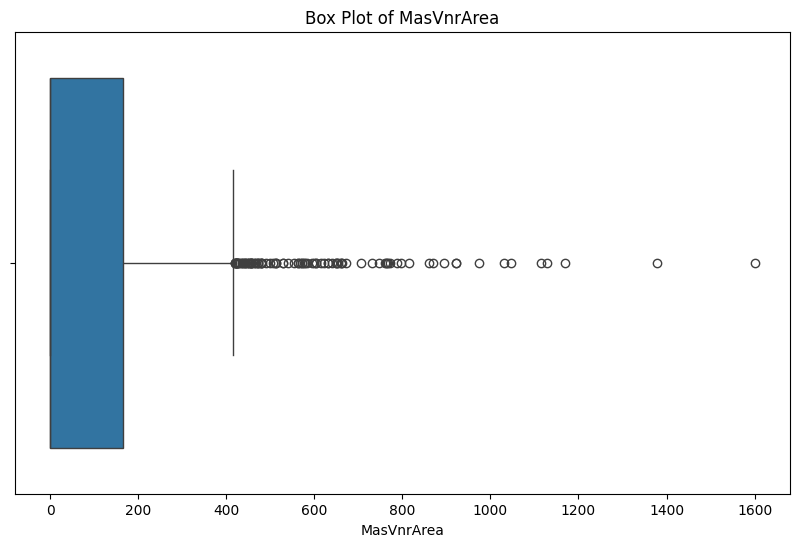

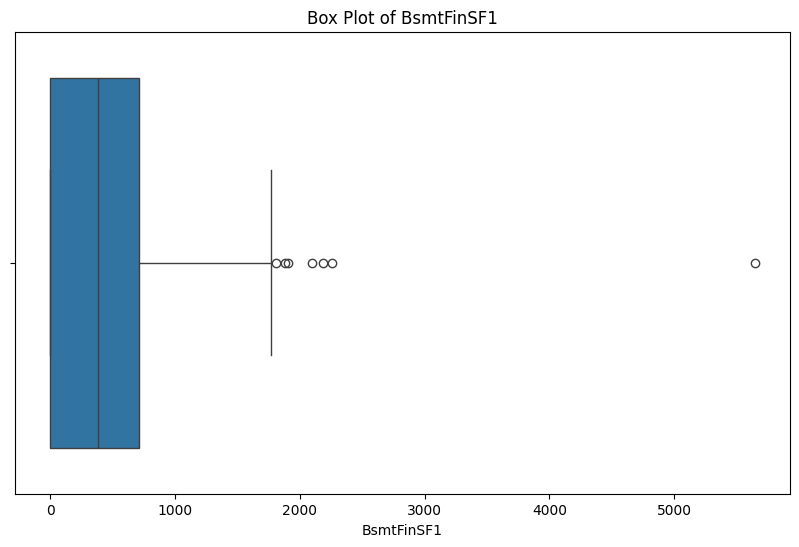

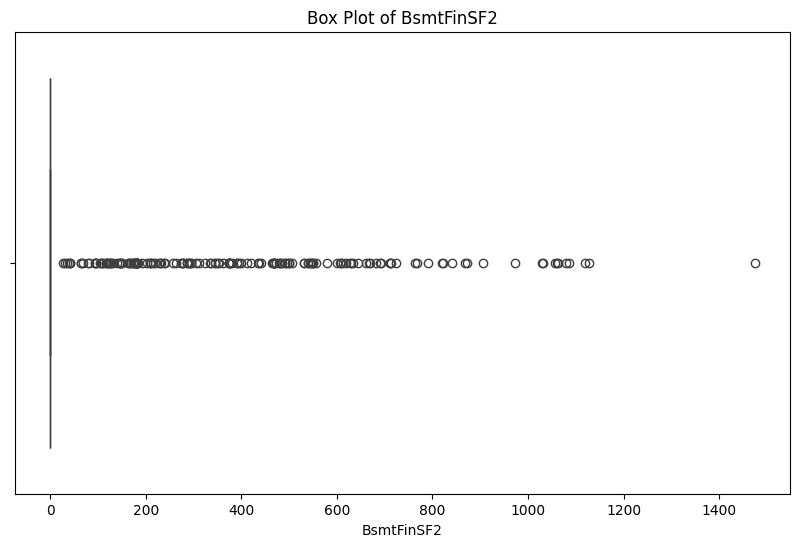

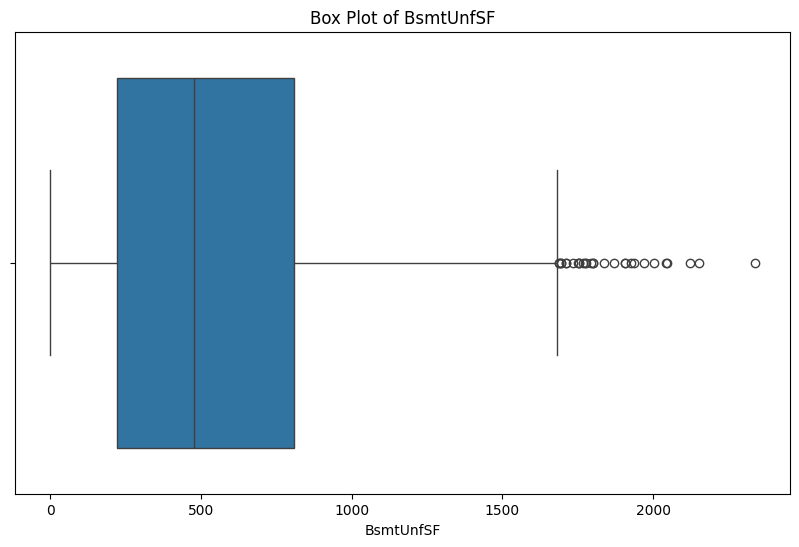

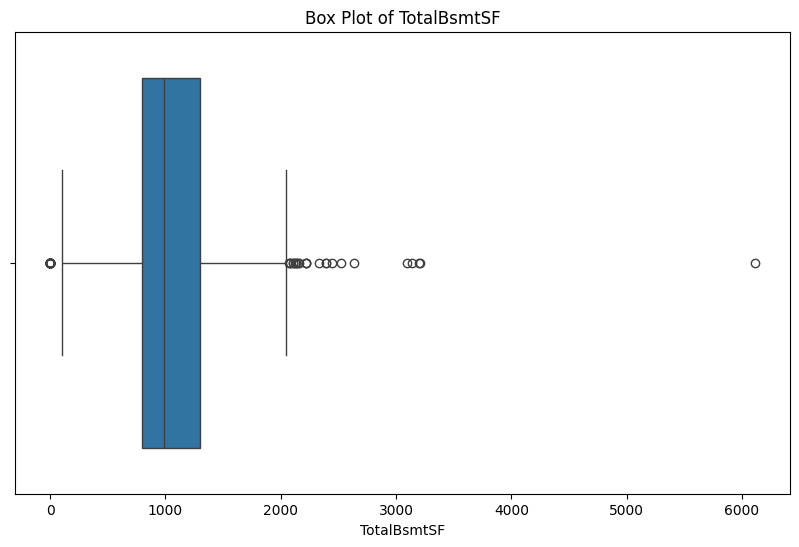

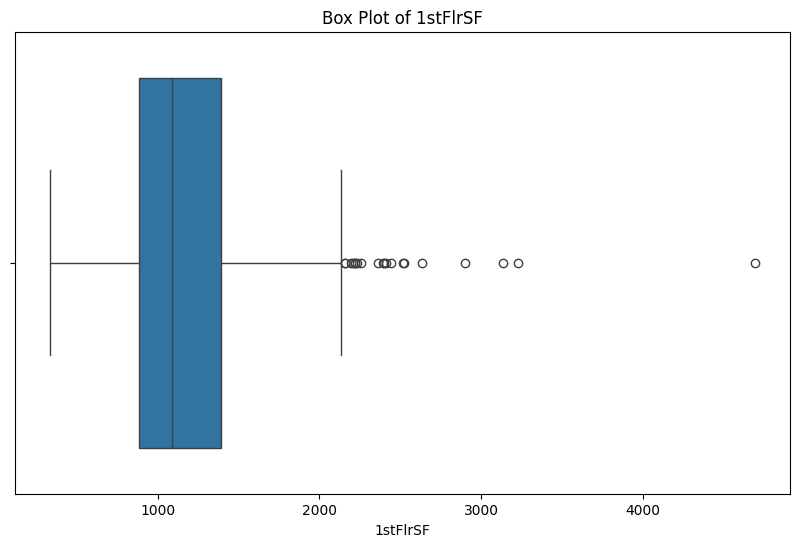

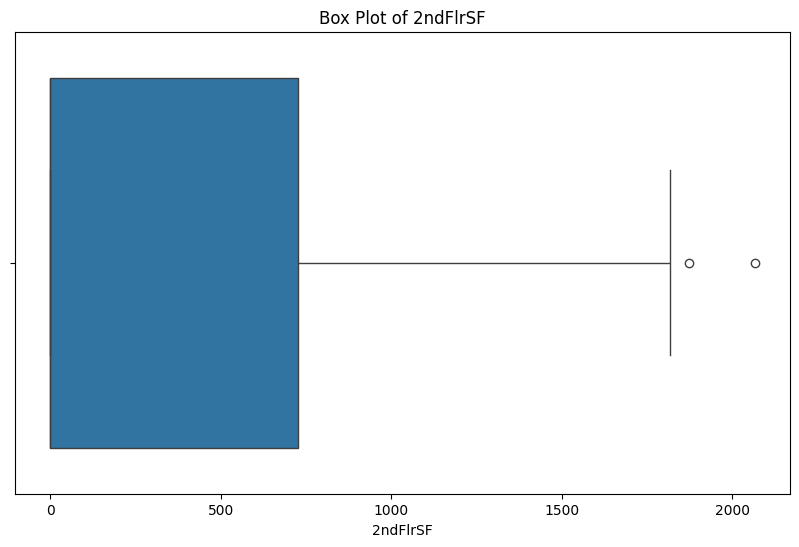

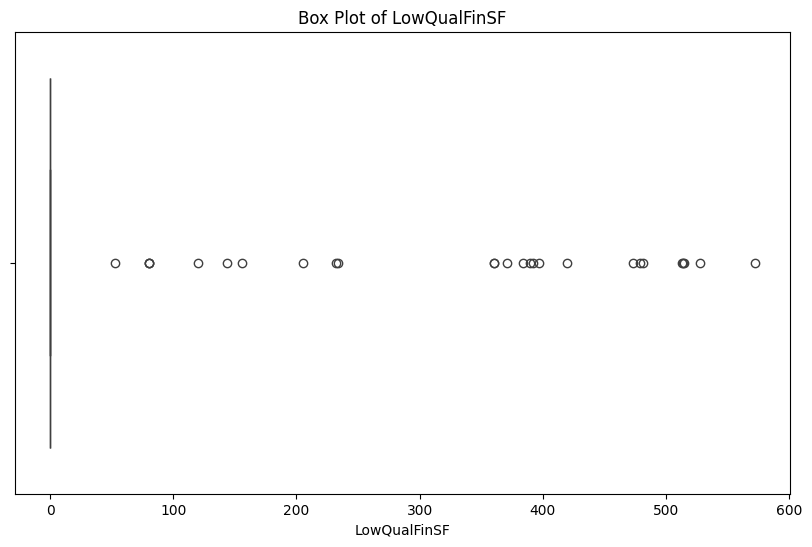

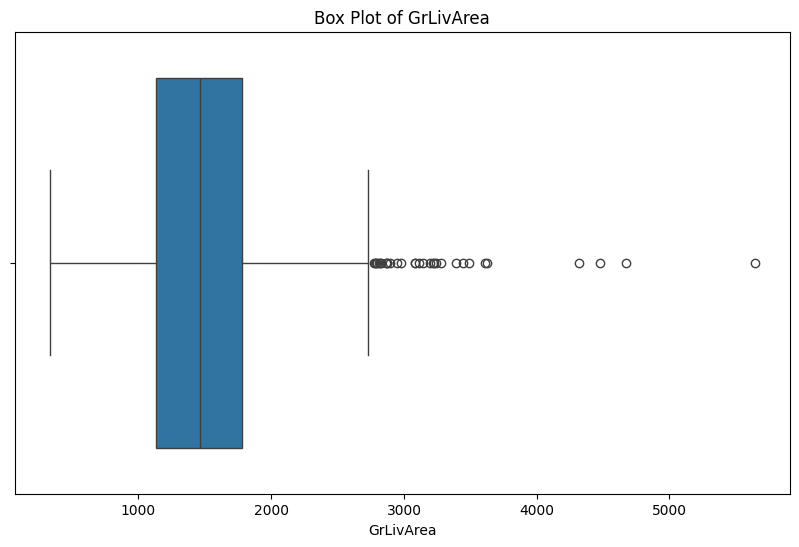

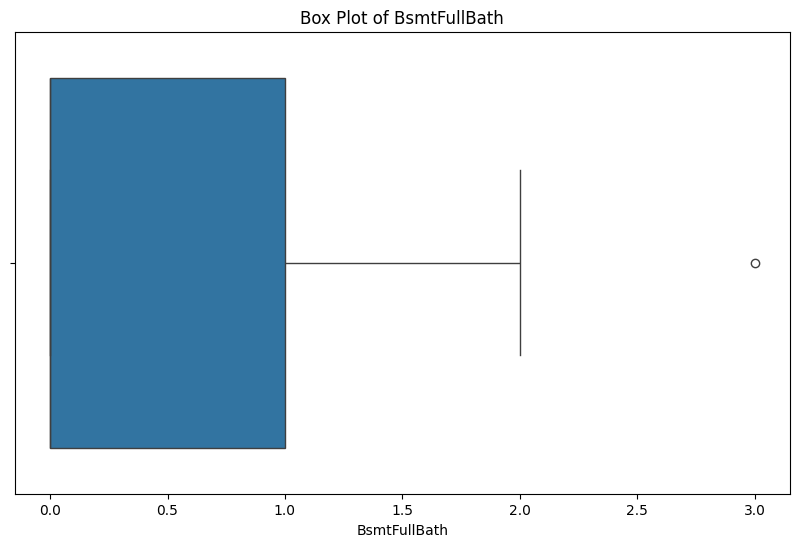

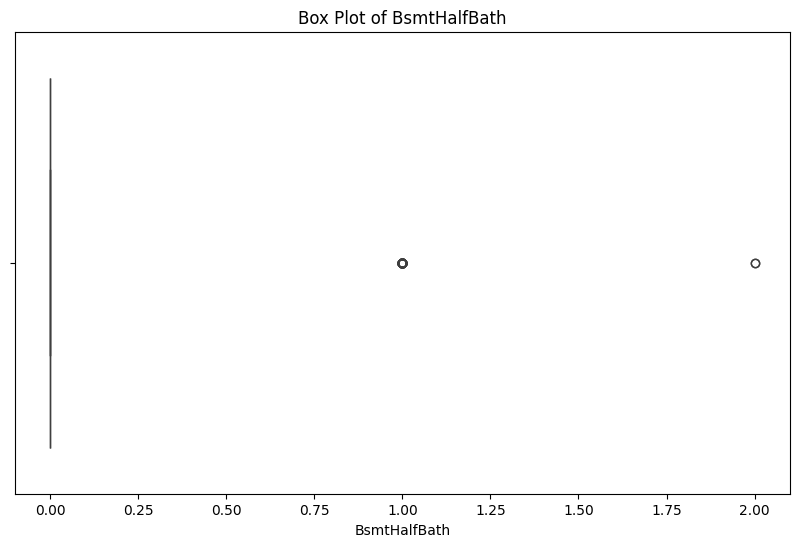

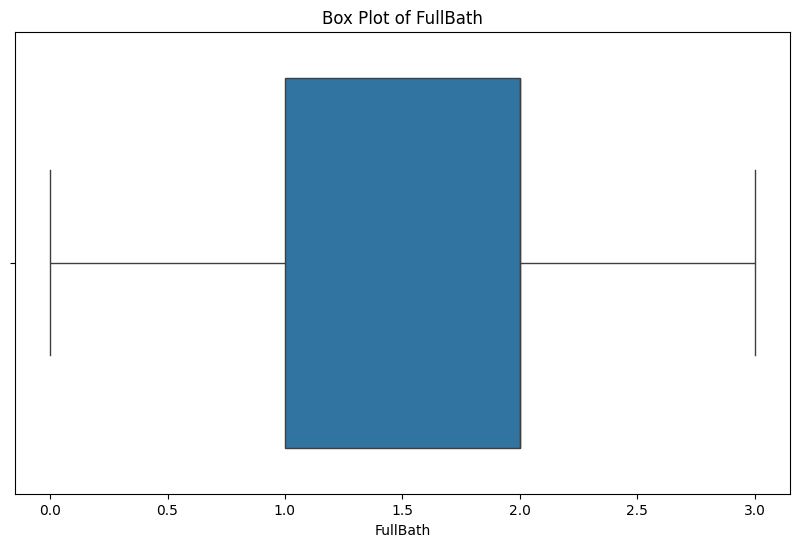

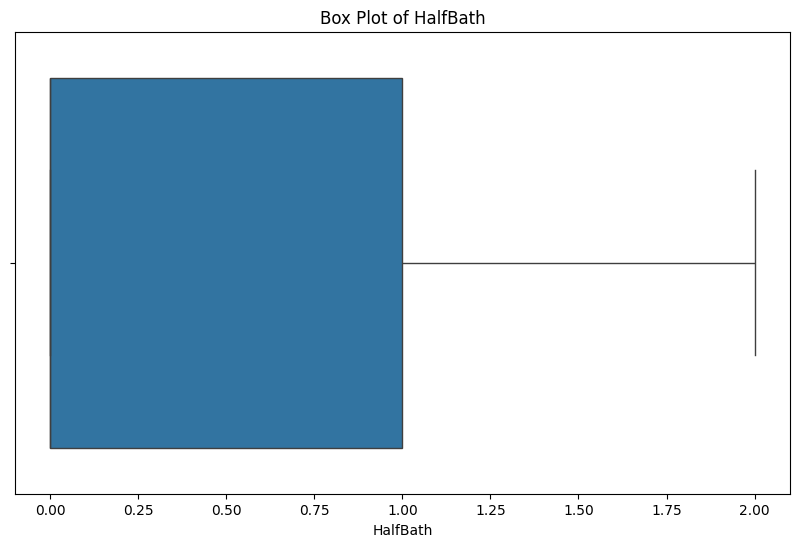

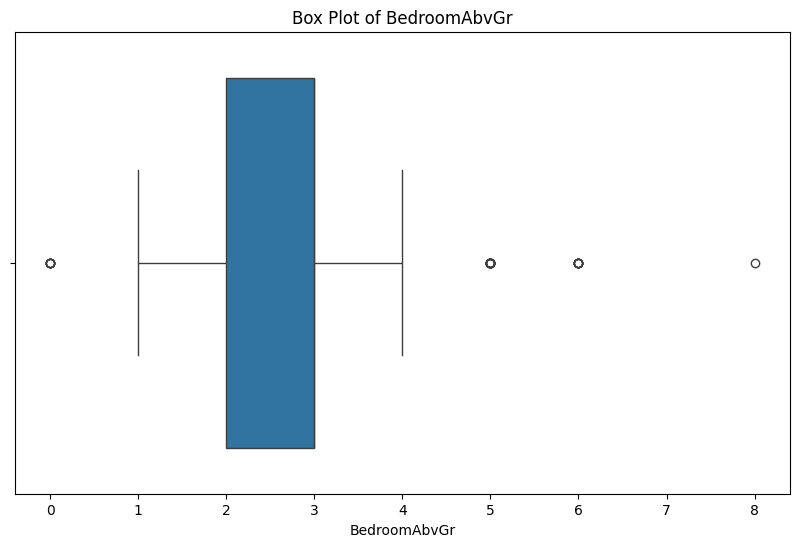

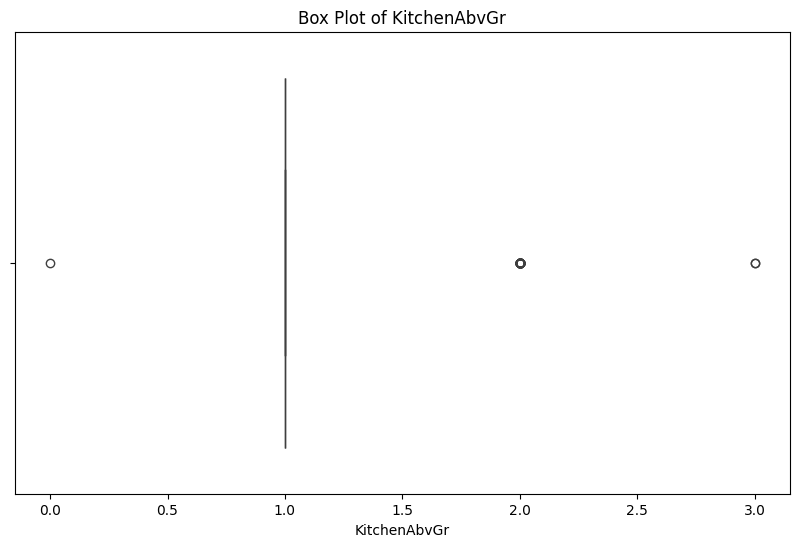

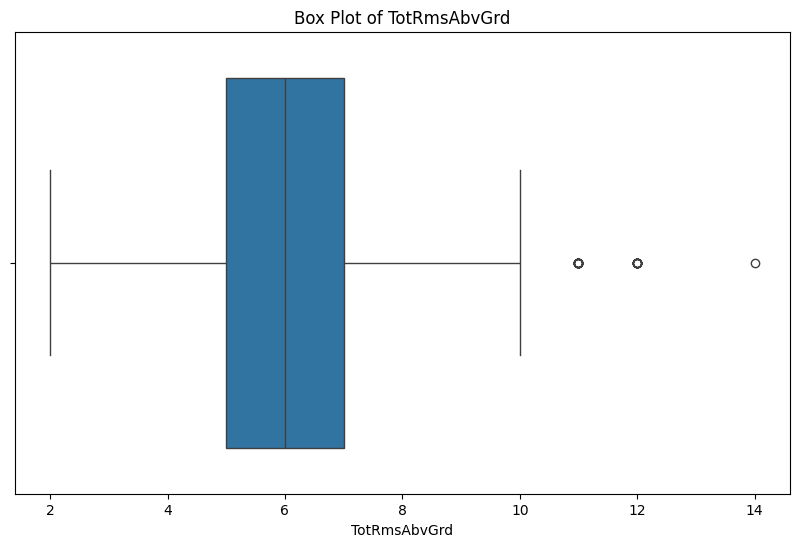

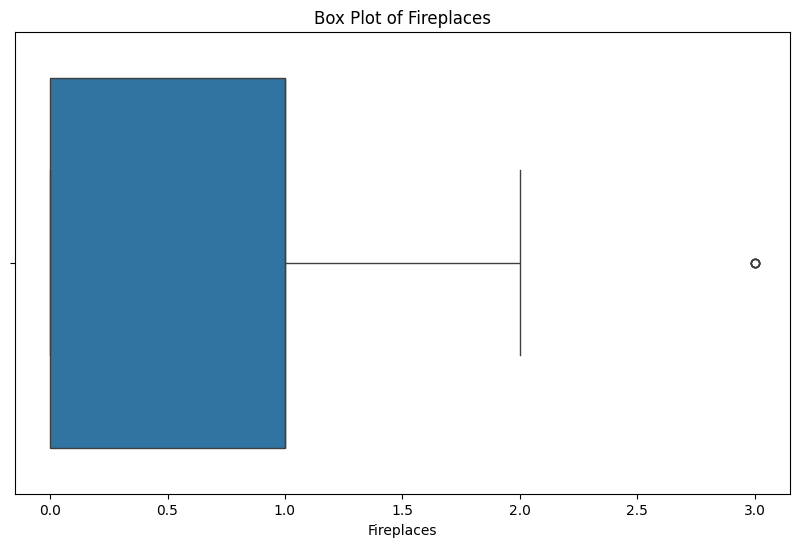

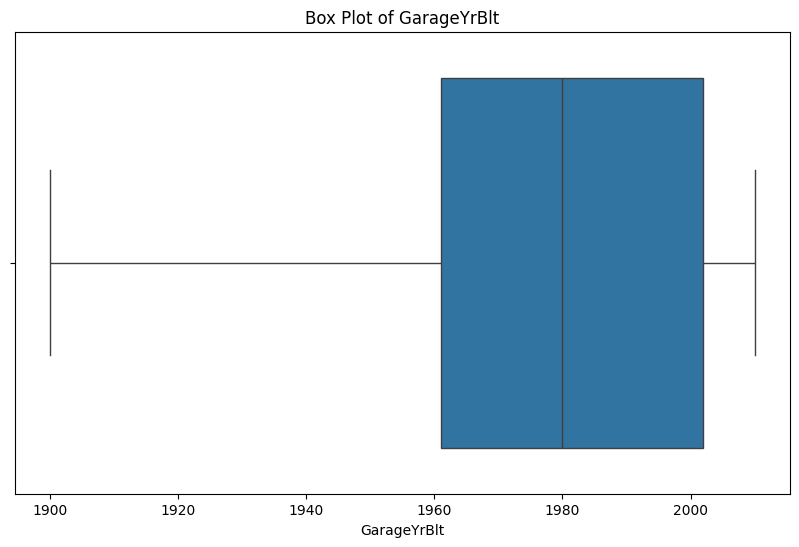

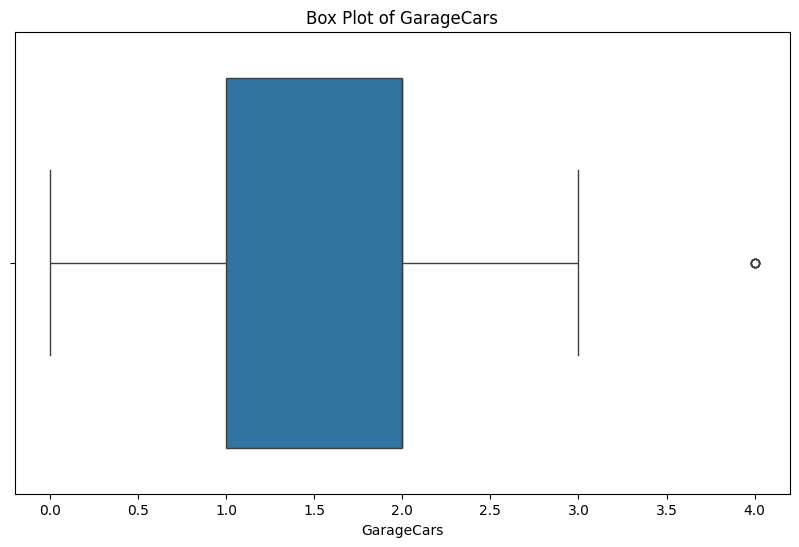

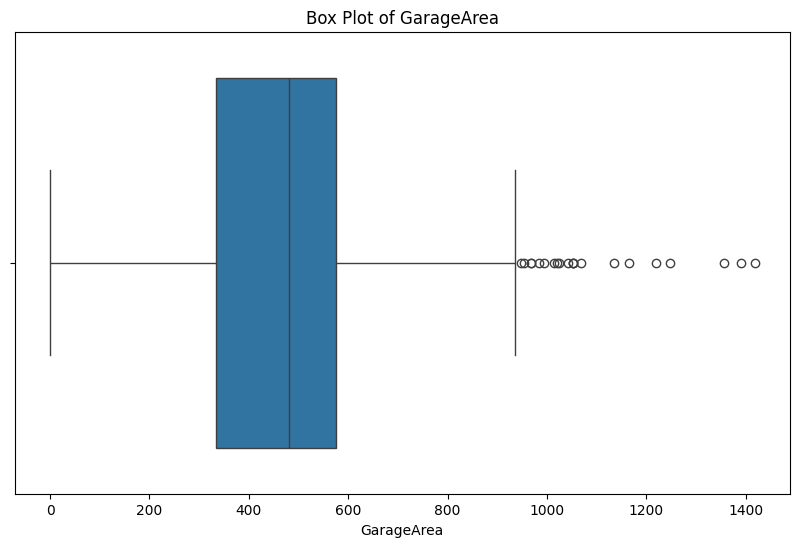

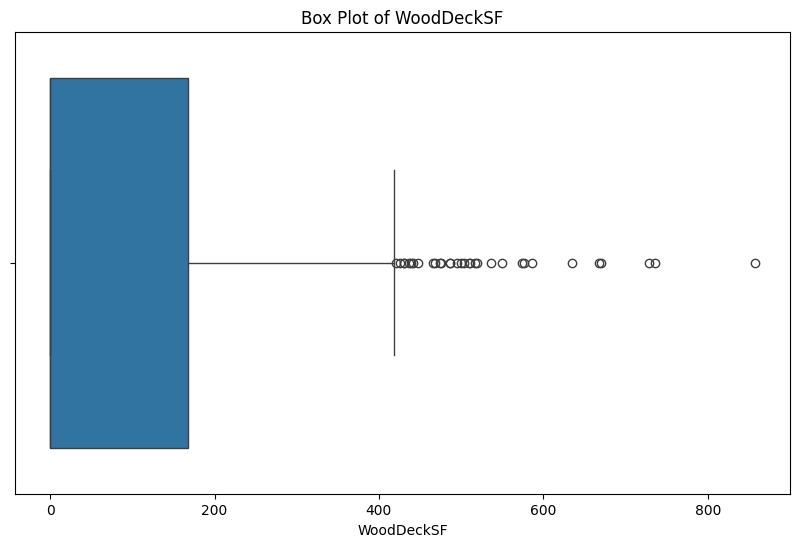

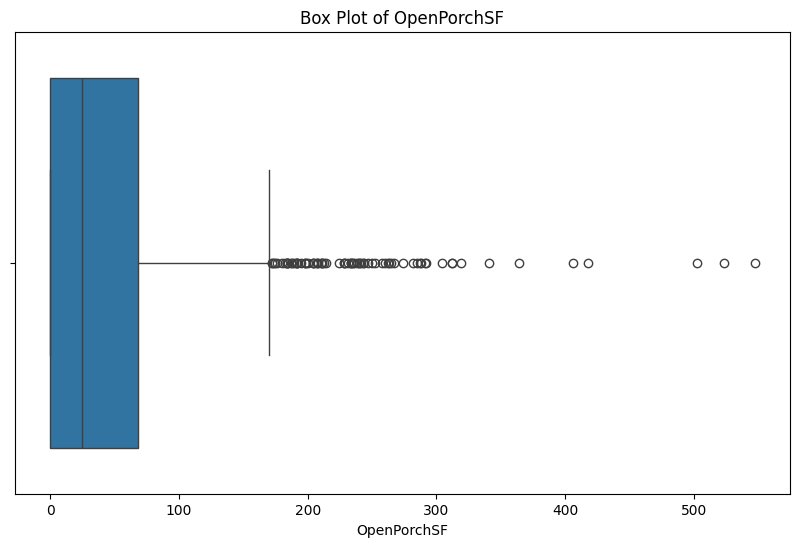

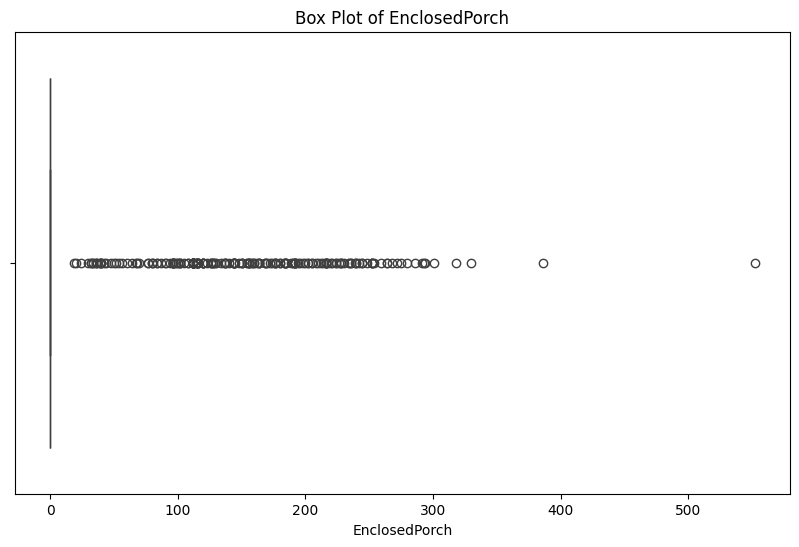

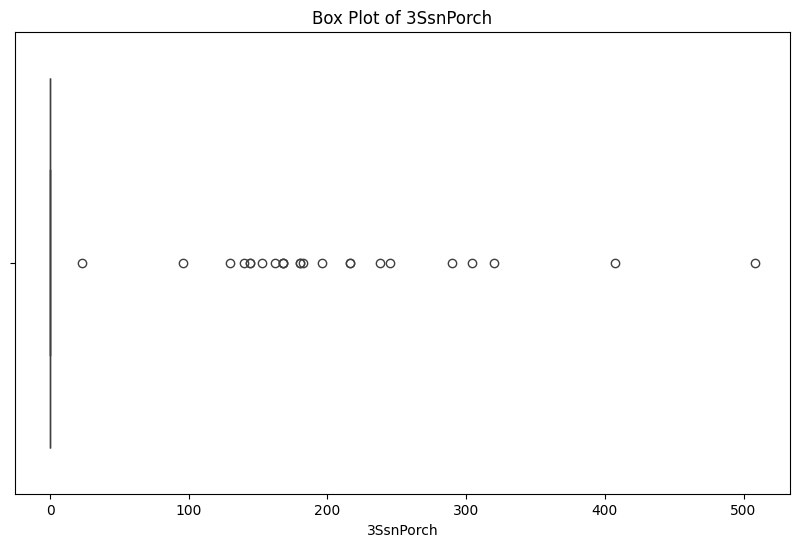

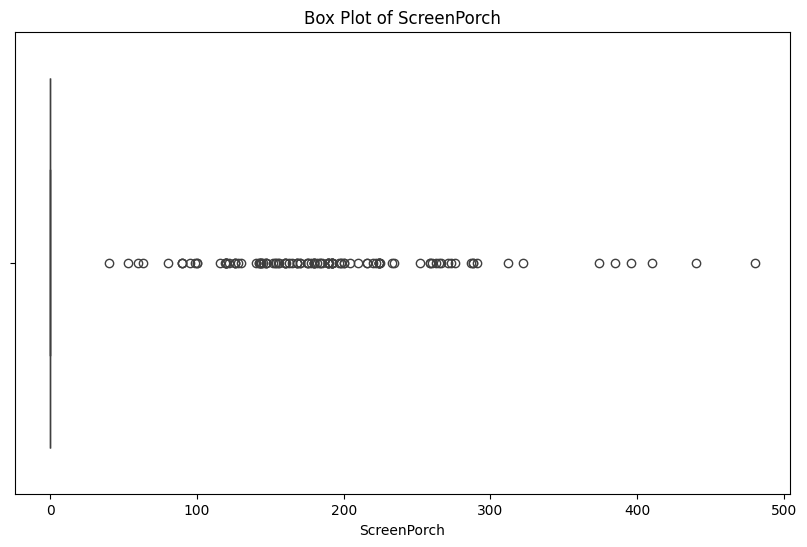

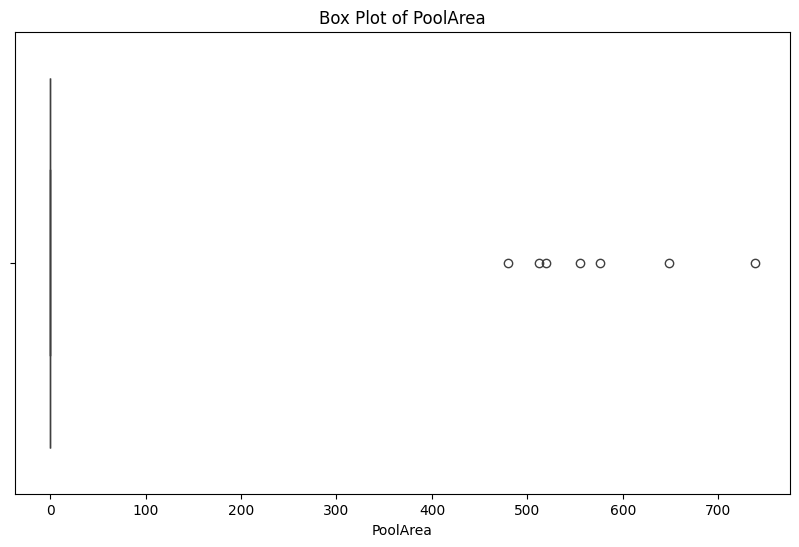

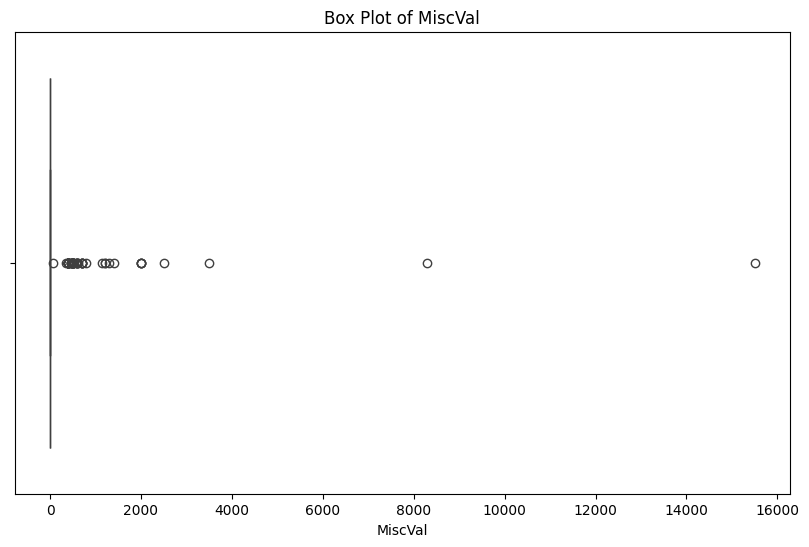

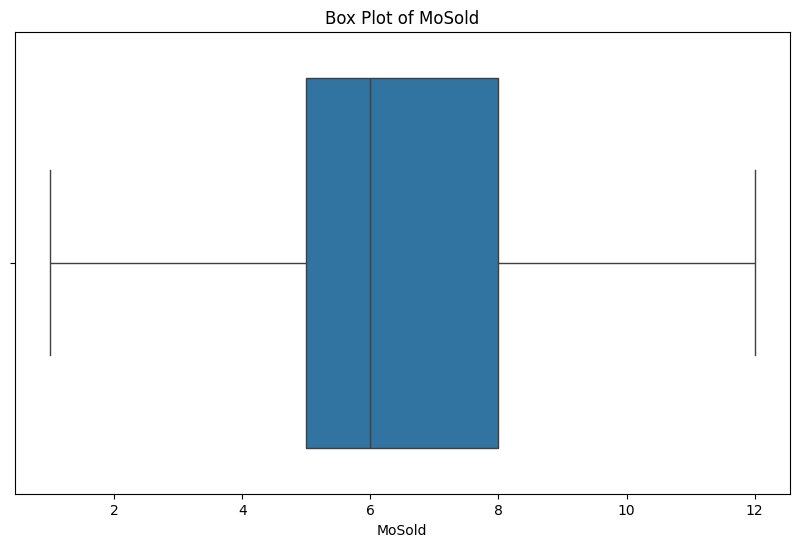

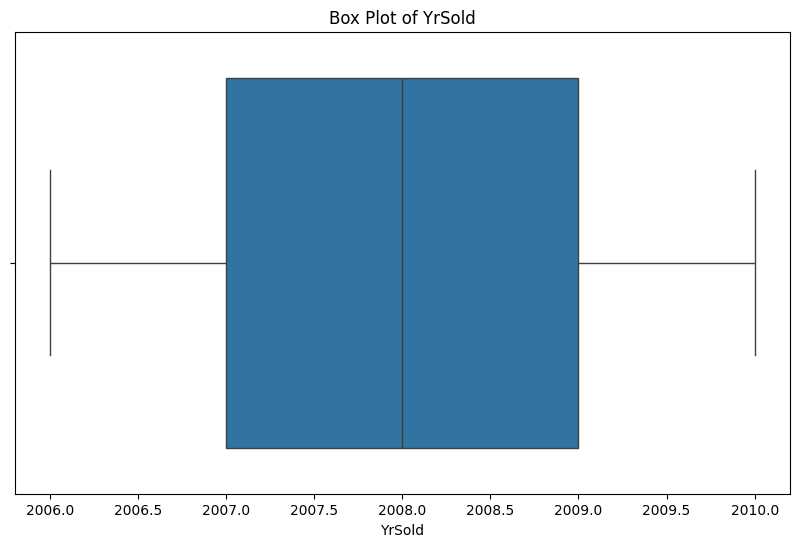

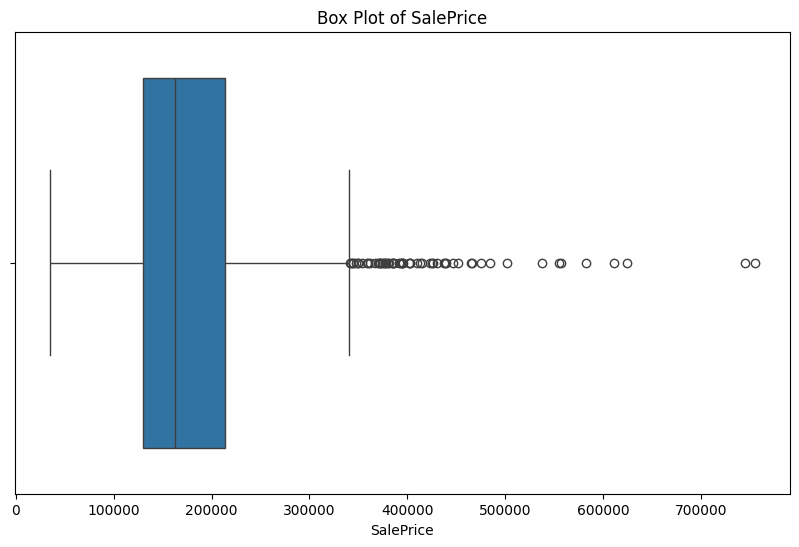

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Pastikan df sudah ada (di materi sebelumnya Anda memakai nama "train")
df = pd.read_csv("train.csv")

# Ambil semua kolom bertipe numerik
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

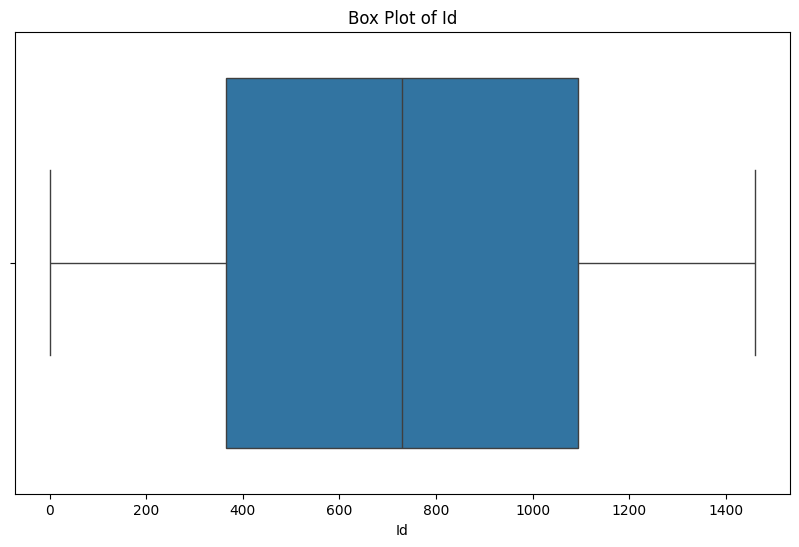

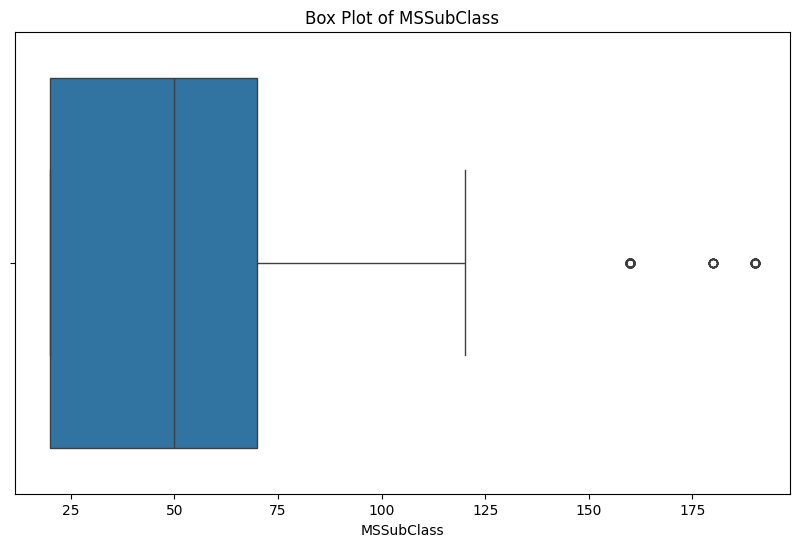

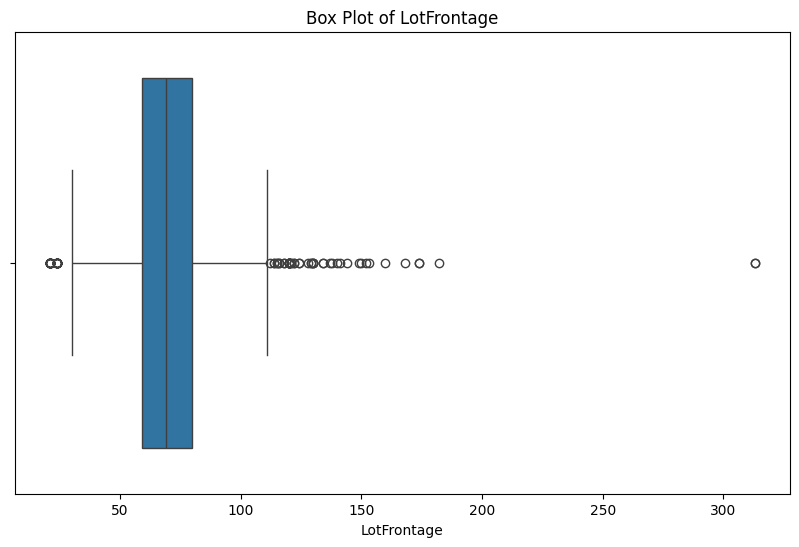

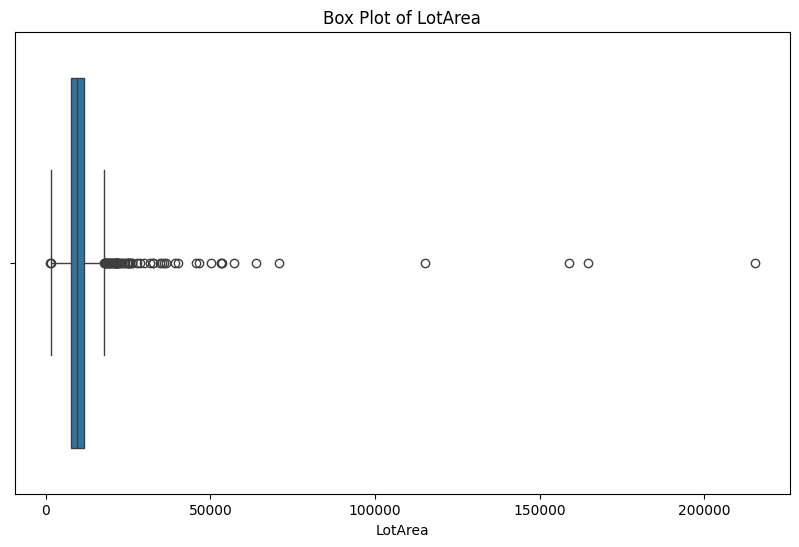

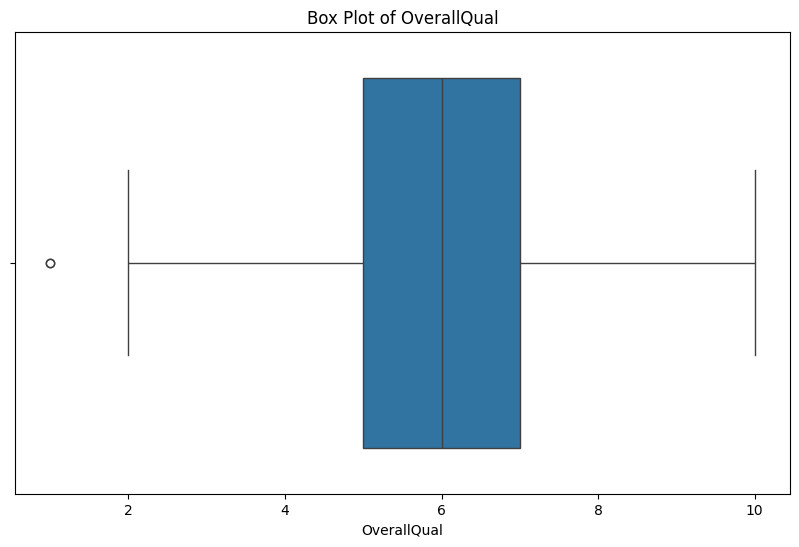

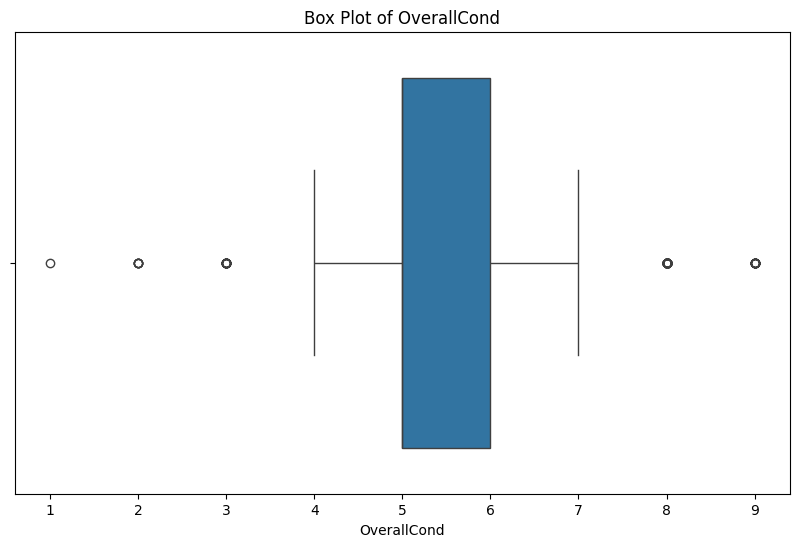

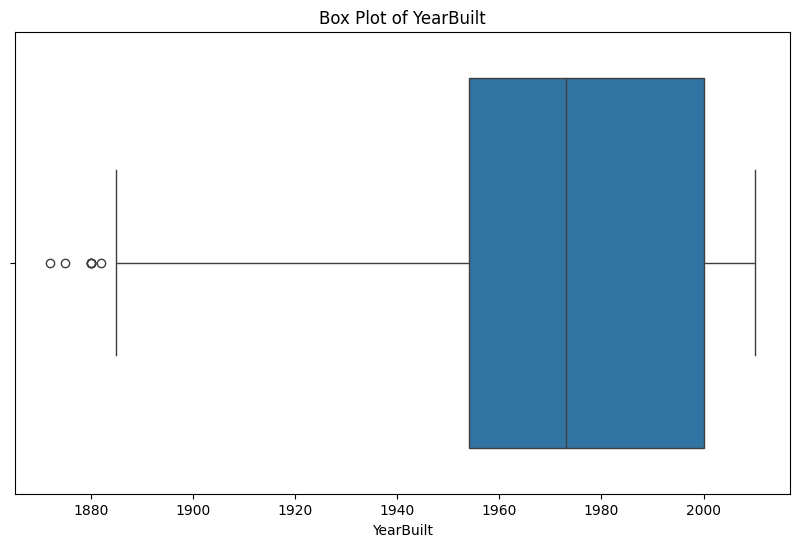

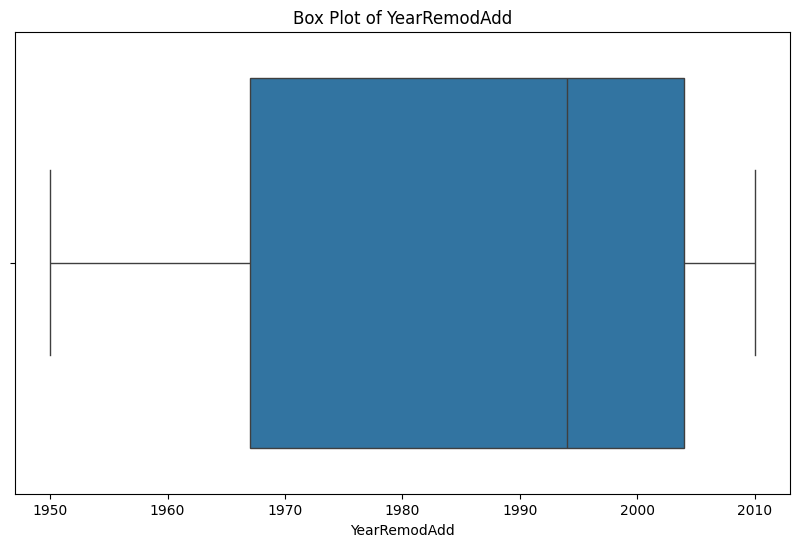

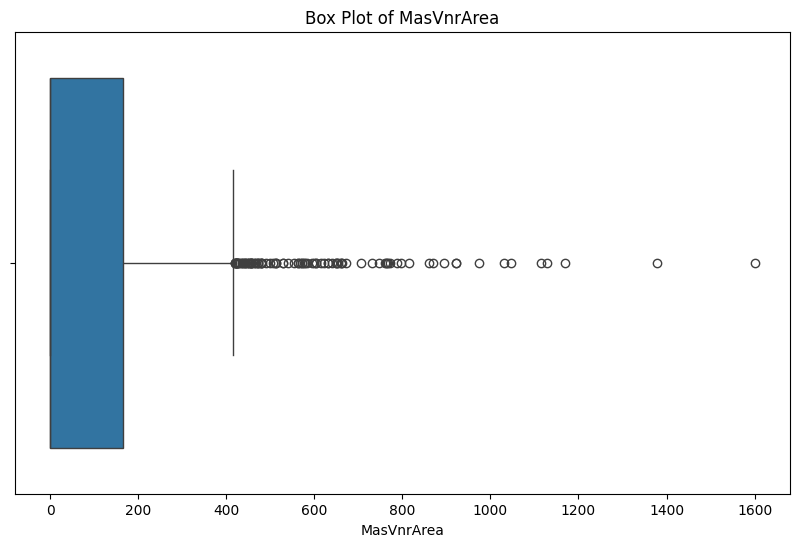

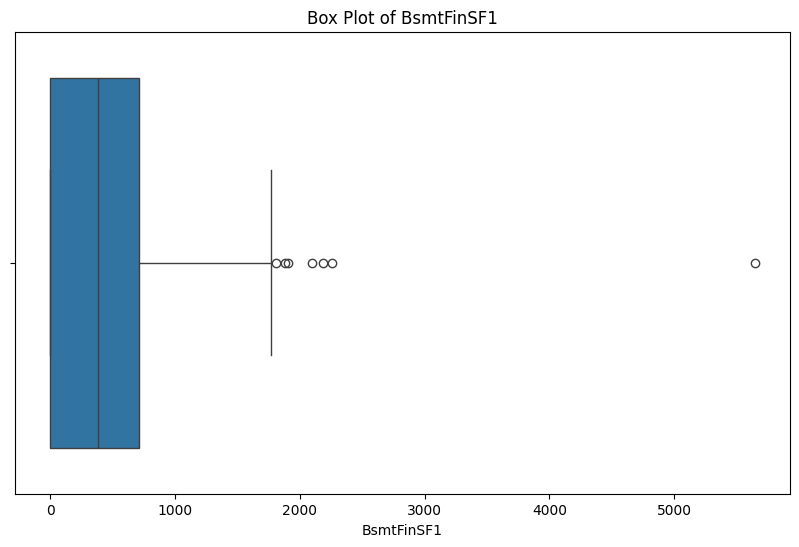

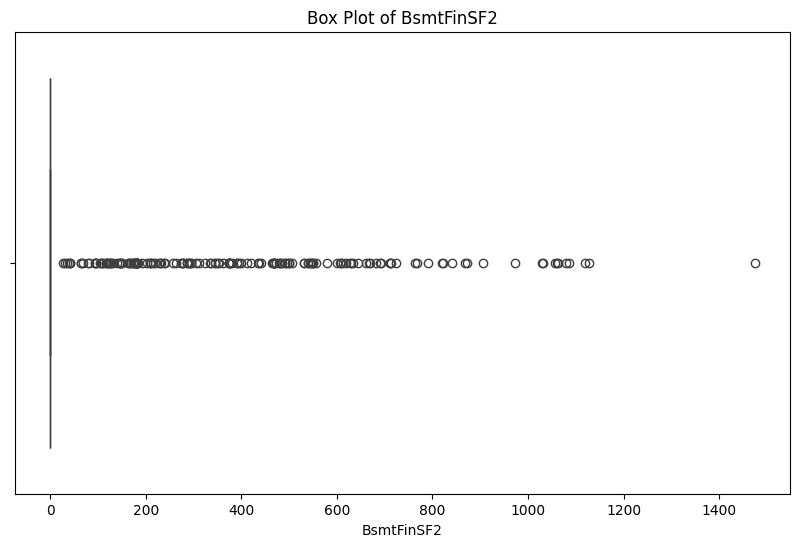

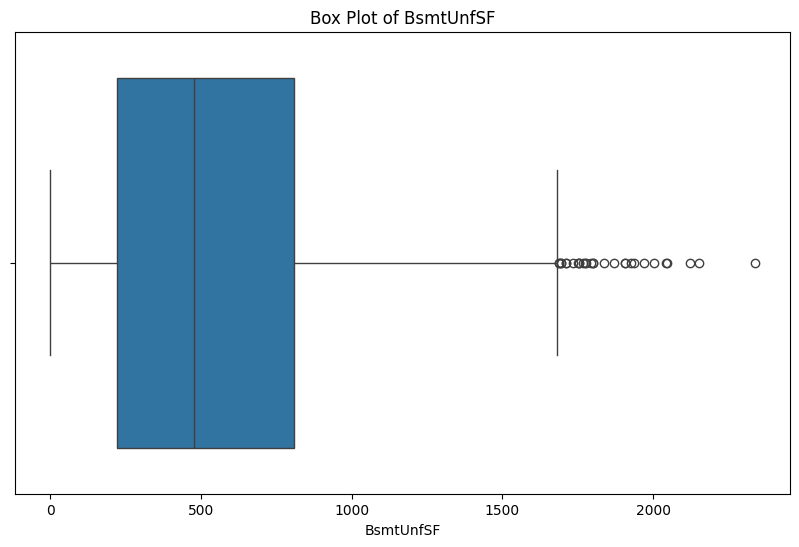

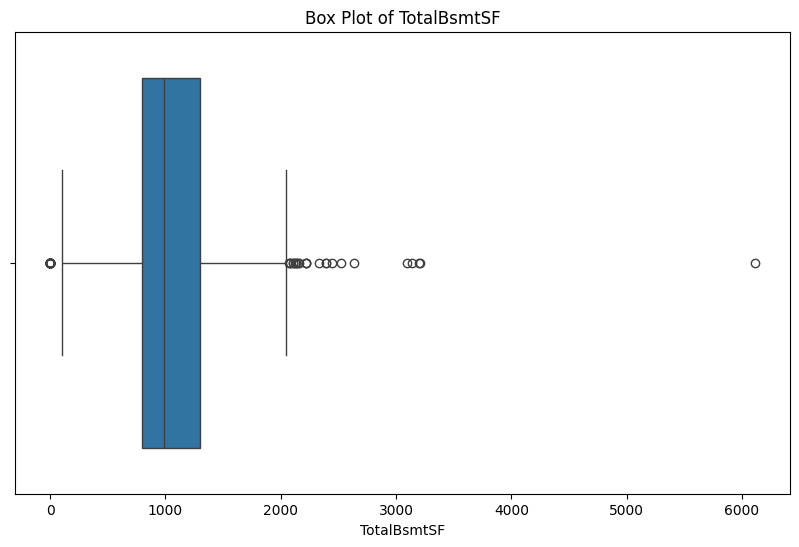

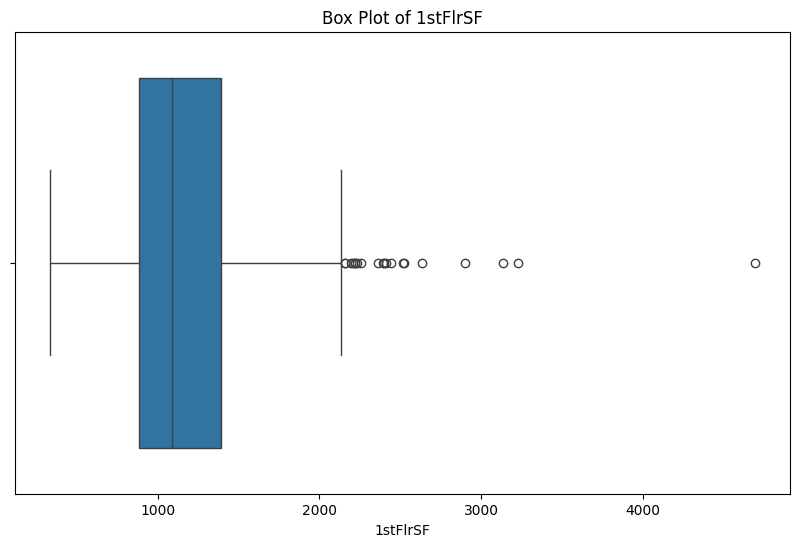

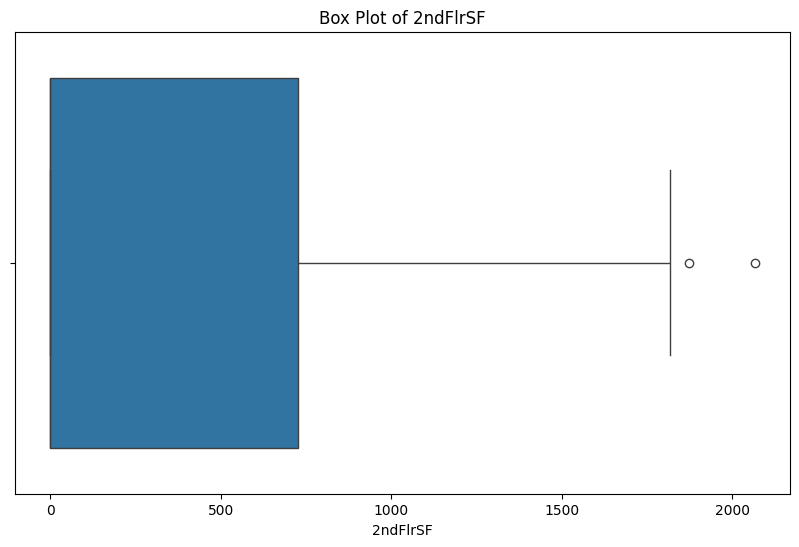

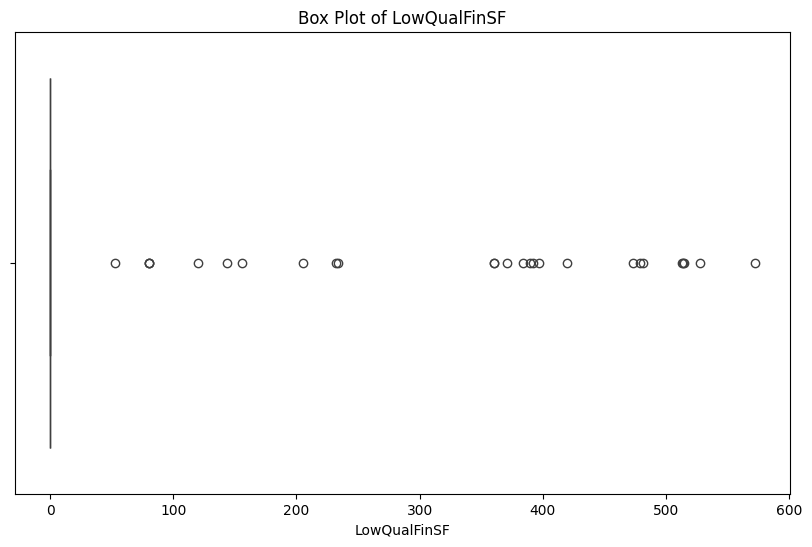

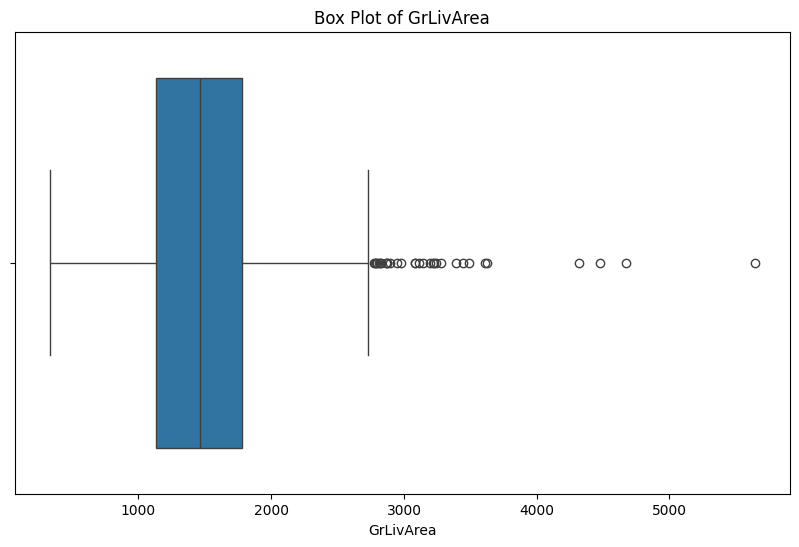

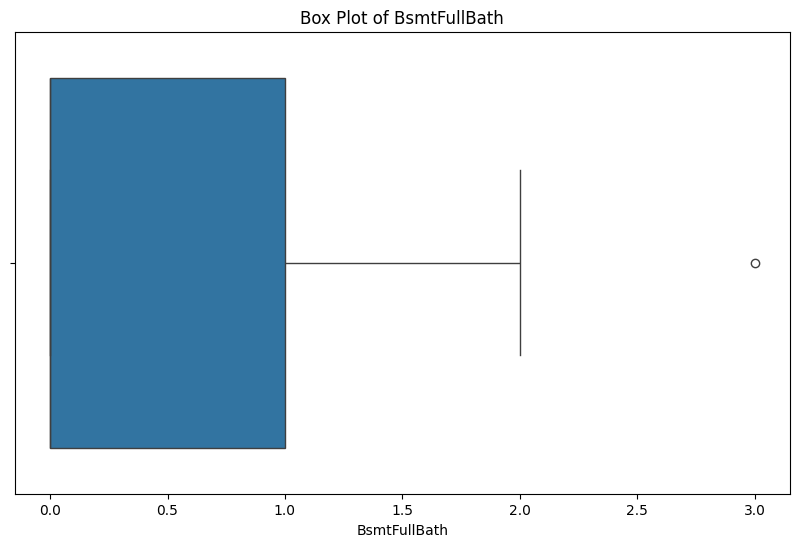

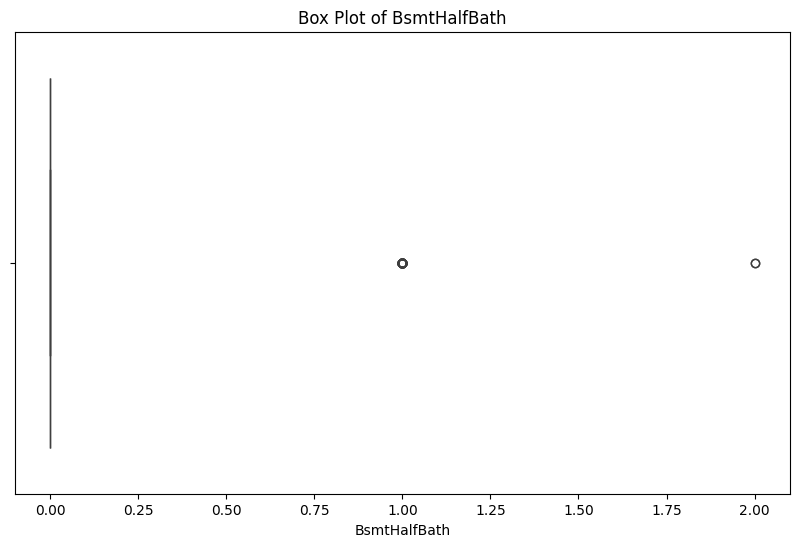

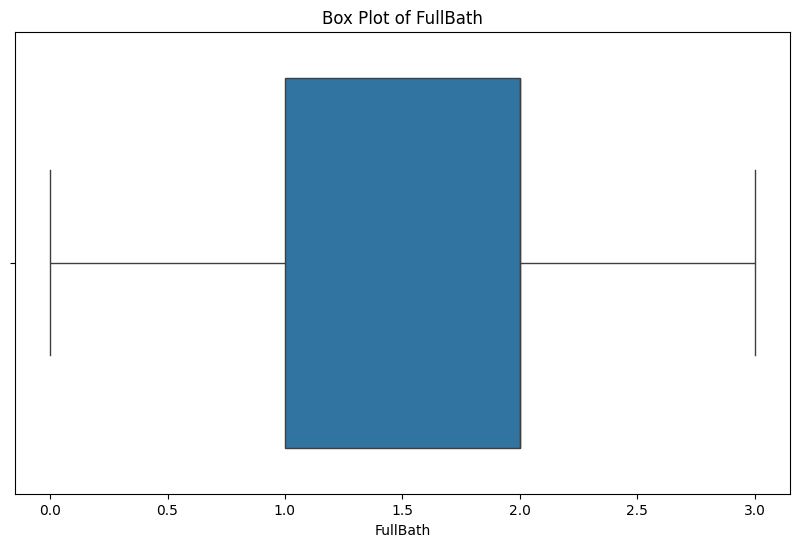

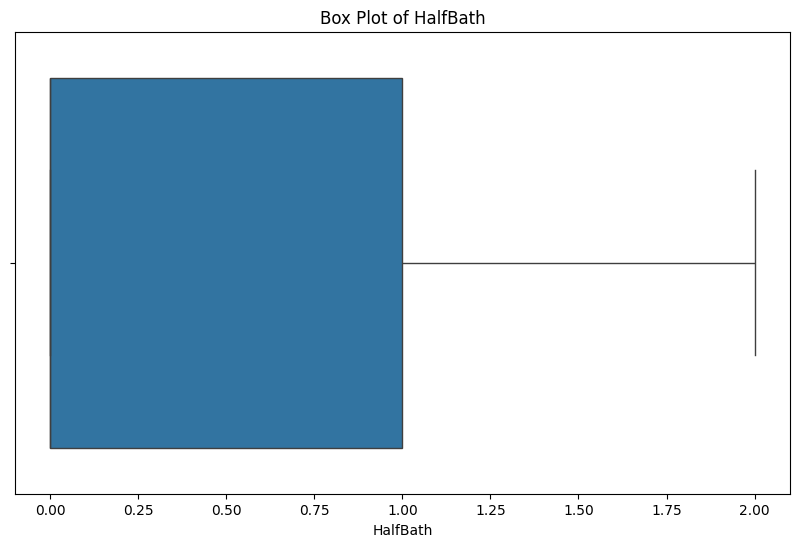

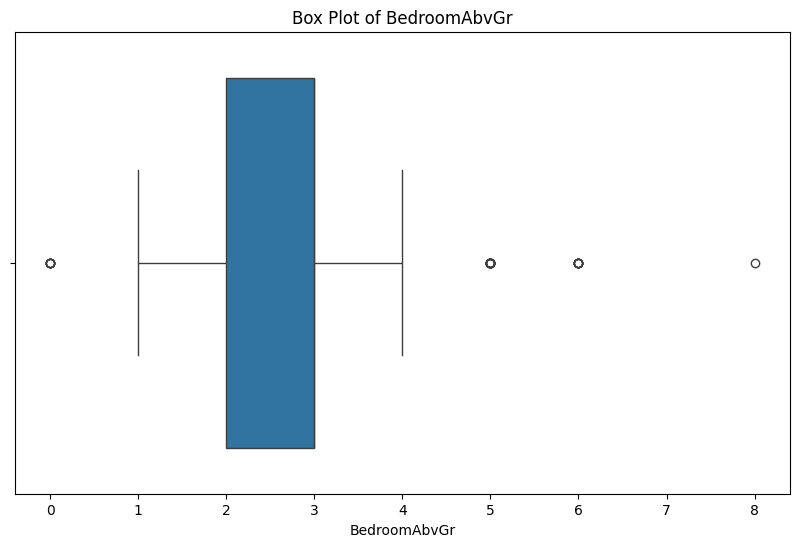

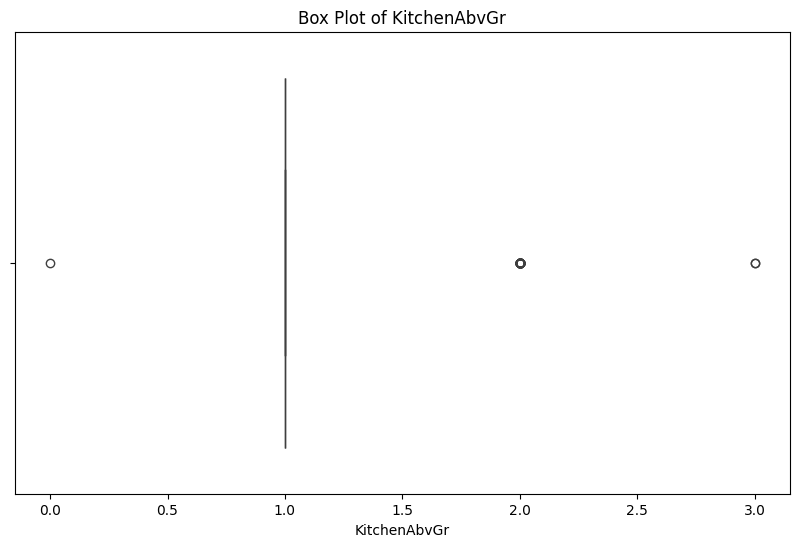

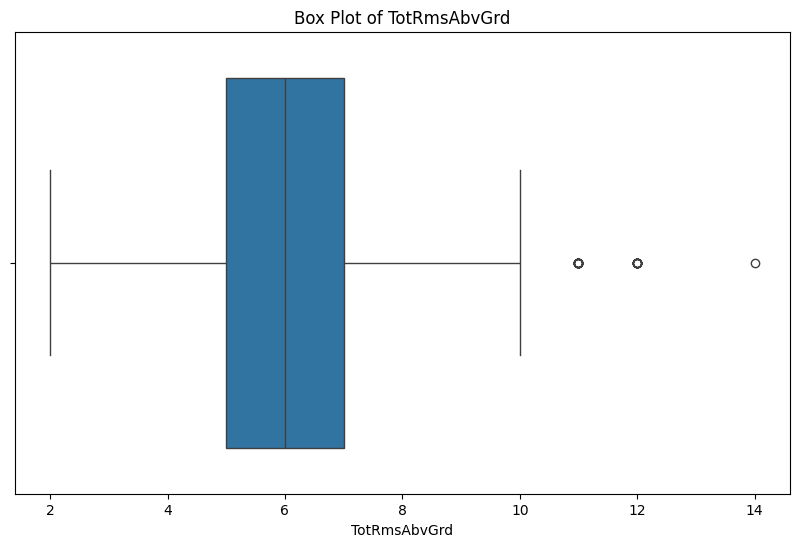

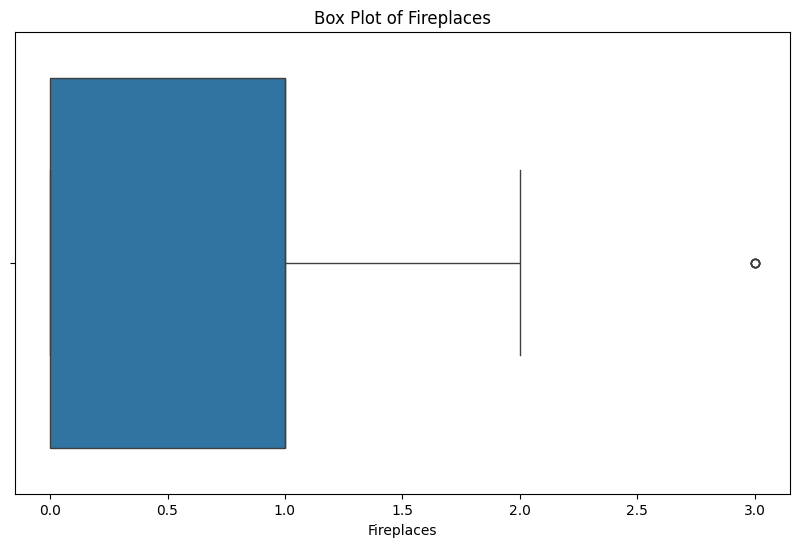

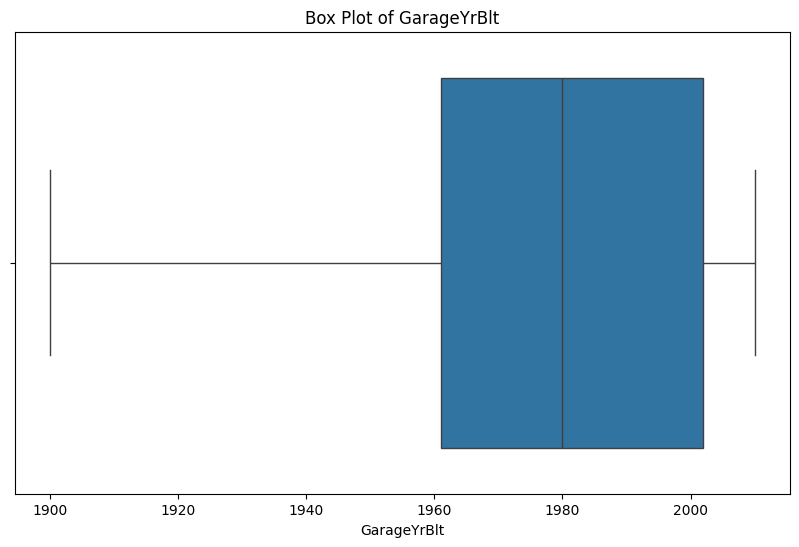

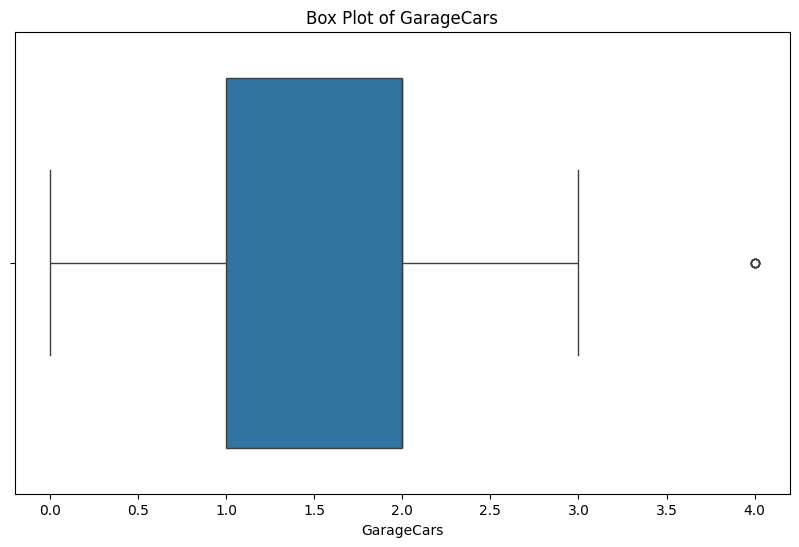

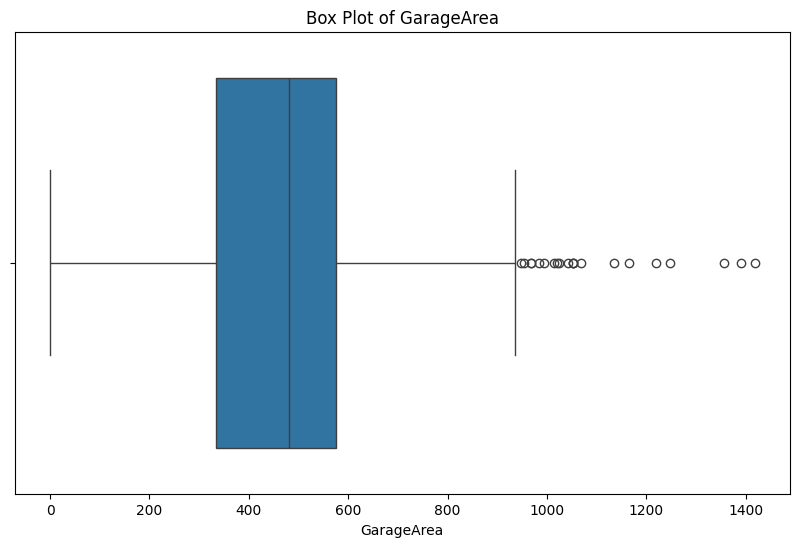

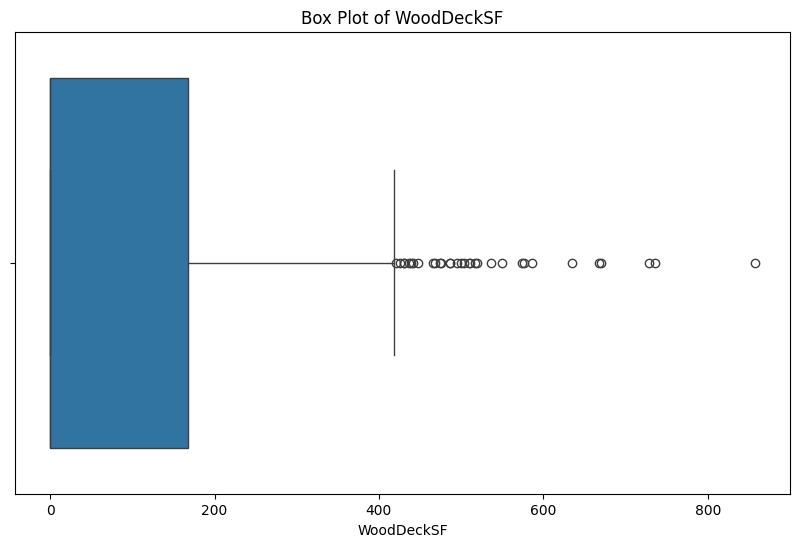

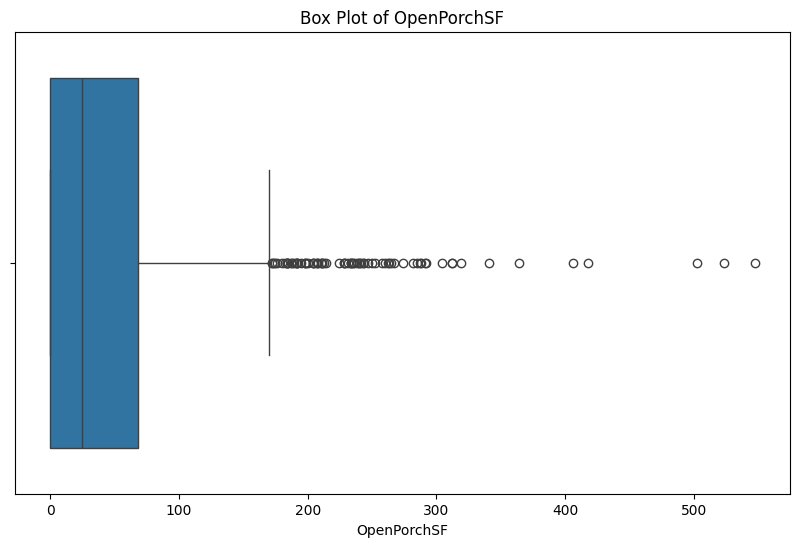

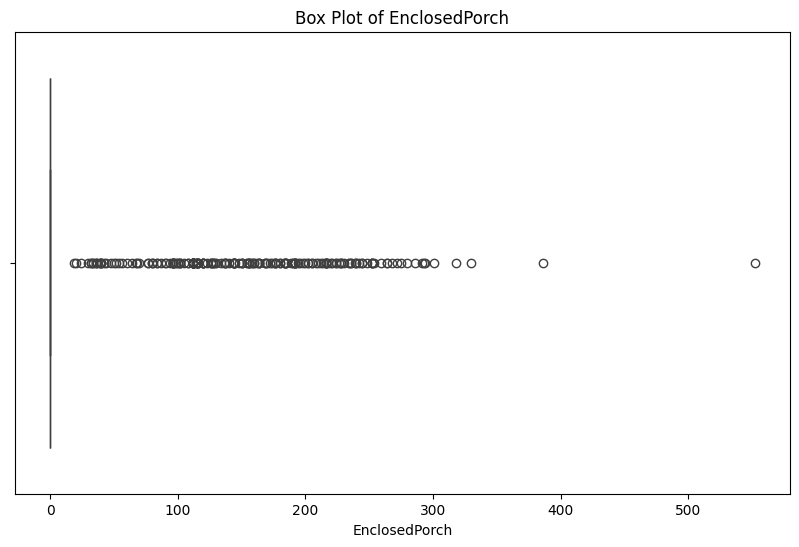

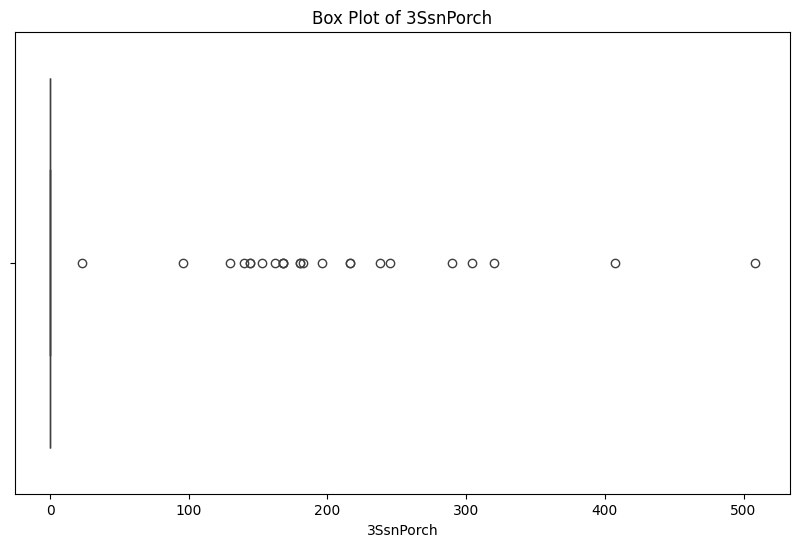

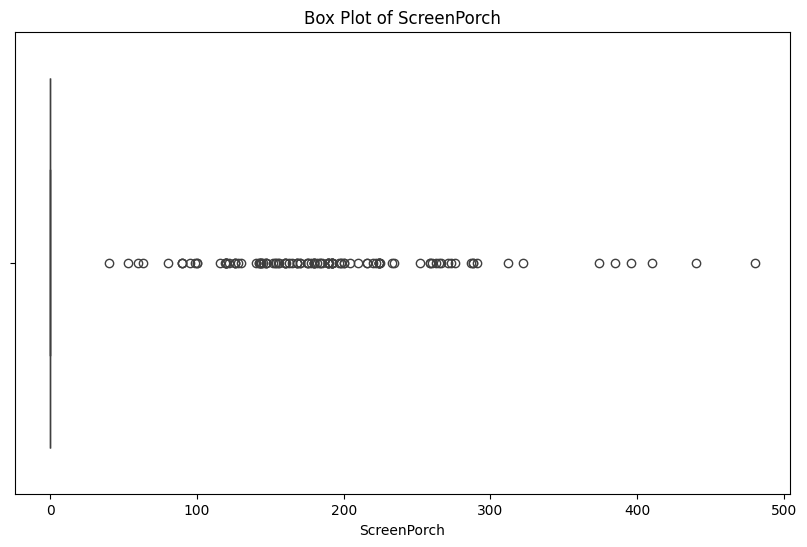

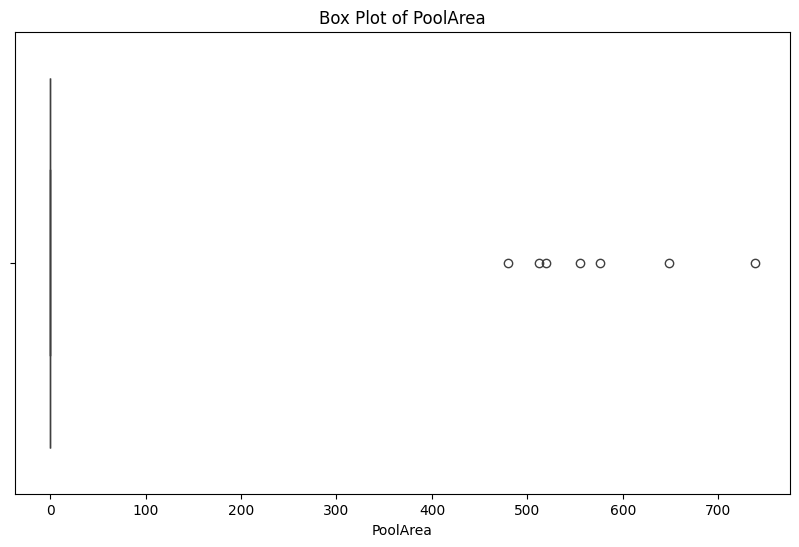

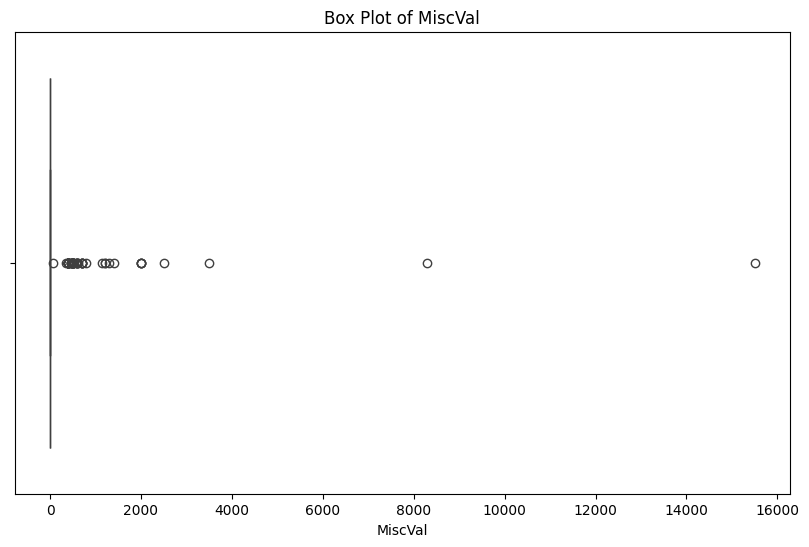

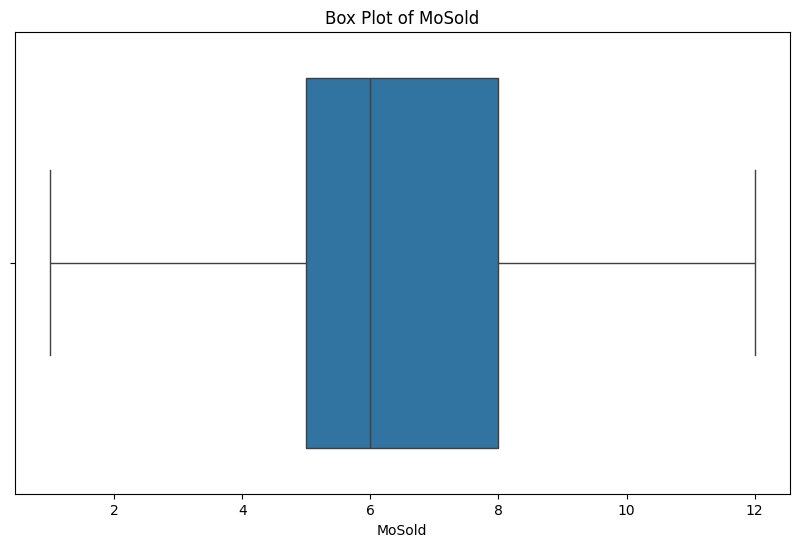

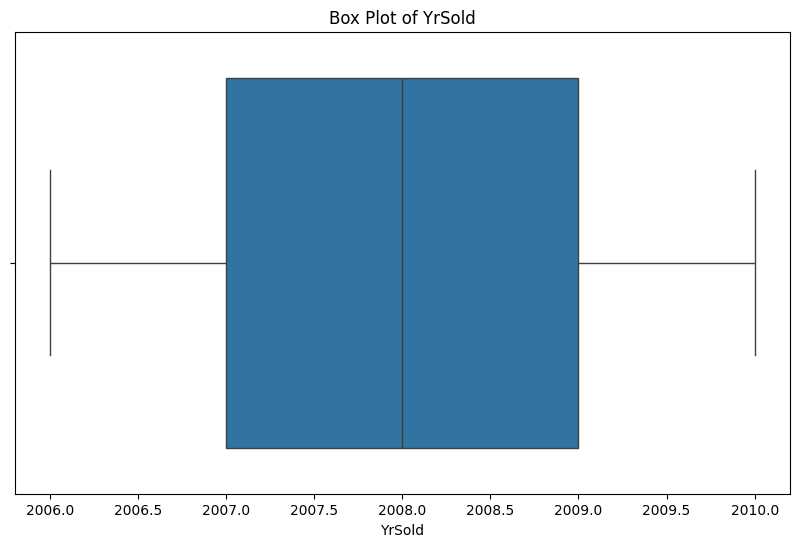

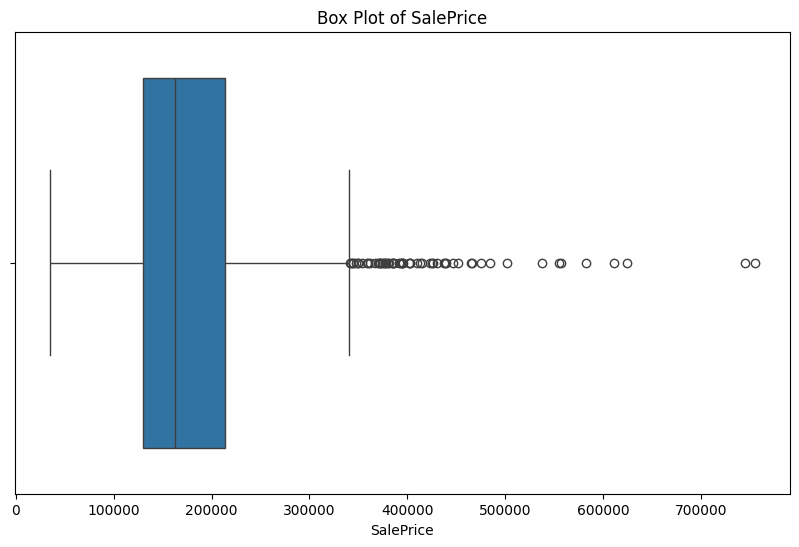

In [11]:
 import pandas as pd
 import seaborn as sns
 import matplotlib.pyplot as plt
  
 for feature in numeric_features:
     plt.figure(figsize=(10, 6))
     sns.boxplot(x=df[feature])
     plt.title(f'Box Plot of {feature}')
     plt.show()

In [12]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [13]:
# 1. Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
# Spasi tersembunyi (U+00A0) sudah dihapus/diketik ulang
condition = ~(
    (df[numeric_features] < (Q1 - 1.5 * IQR)) | 
    (df[numeric_features] > (Q3 + 1.5 * IQR))
).any(axis=1)

df_filtered_numeric = df.loc[condition, numeric_features]

# 2. Menggabungkan kembali dengan kolom kategorikal
# Mengubah 'str' menjadi 'object' agar sesuai tipe data pandas
categorical_features = df.select_dtypes(include=['str']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [14]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

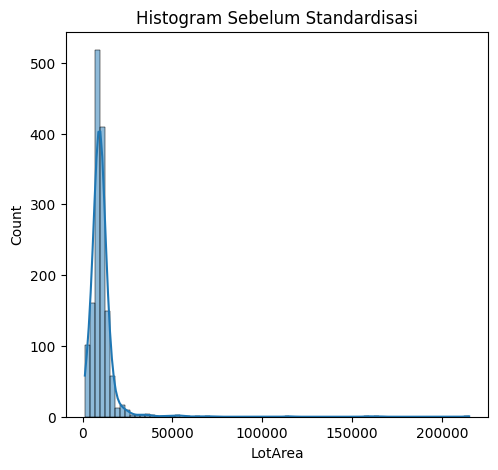

In [15]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

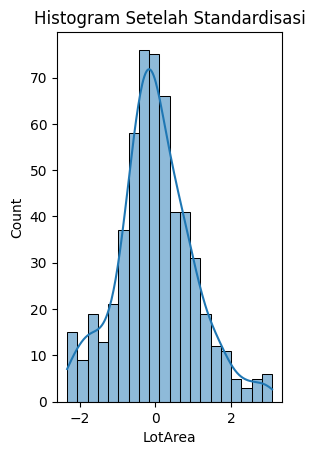

In [16]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [17]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Id, MSSubClass, LotFrontage, LotArea, OverallQual, OverallCond, YearBuilt, YearRemodAdd, MasVnrArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, BsmtFullBath, BsmtHalfBath, FullBath, HalfBath, BedroomAbvGr, KitchenAbvGr, TotRmsAbvGrd, Fireplaces, GarageYrBlt, GarageCars, GarageArea, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, MiscVal, MoSold, YrSold, SalePrice, MSZoning, Street, Alley, LotShape, LandContour, Utilities, LotConfig, LandSlope, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, ExterQual, ExterCond, Foundation, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2, Heating, HeatingQC, CentralAir, Electrical, KitchenQual, Functional, FireplaceQu, GarageType, GarageFinish, GarageQual, GarageCond, PavedDrive, PoolQC, Fence, MiscFeature, SaleType, SaleCondition]
Index: []

[0 rows x 8

In [18]:
# Menghapus baris duplikat
df = df.drop_duplicates()
  
print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
            Id  MSSubClass  LotFrontage   LotArea  OverallQual  OverallCond  \
0    -1.759808    0.355555    -0.235460 -0.283781     0.603741    -0.520119   
2    -1.755051    0.355555    -0.035640  0.743896     0.603741    -0.520119   
4    -1.750293    0.355555     1.030064  1.848648     1.403520    -0.520119   
6    -1.745536   -0.917435     0.430605  0.315942     1.403520    -0.520119   
10   -1.736022   -0.917435     0.097573  0.725544    -0.995817    -0.520119   
...        ...         ...          ...       ...          ...          ...   
1448  1.684452    0.037308     0.097573  0.933649    -1.795596     2.322862   
1451  1.691588   -0.917435     0.630425  0.014246     1.403520    -0.520119   
1453  1.696345   -0.917435     1.429703  2.933948    -0.995817    -0.520119   
1454  1.698724   -0.917435    -0.435279 -0.632456     0.603741    -0.520119   
1455  1.701103    0.355555    -0.435279 -0.479406    -0.196038    -0.520119   

      YearBui

In [19]:
category_features = df.select_dtypes(include=['str']).columns
df[category_features]

,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
0,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
2,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
4,RL,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
6,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
10,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,...,Detchd,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1448,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Edwards,Norm,...,Detchd,Unf,Fa,TA,Y,NaN,GdWo,NaN,WD,Normal
1451,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,Attchd,Fin,TA,TA,Y,NaN,NaN,NaN,New,Partial
1453,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,...,NaN,NaN,NaN,NaN,Y,NaN,NaN,NaN,WD,Abnorml
1454,FV,Pave,Pave,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal


In [20]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,-1.759808,0.355555,-0.235460,-0.283781,0.603741,-0.520119,0.784375,0.703197,1.139363,0.636075,...,False,False,False,False,True,False,False,False,True,False
2,-1.755051,0.355555,-0.035640,0.743896,0.603741,-0.520119,0.704671,0.652106,0.819031,0.099558,...,False,False,False,False,True,False,False,False,True,False
4,-1.750293,0.355555,1.030064,1.848648,1.403520,-0.520119,0.664818,0.549925,2.590278,0.511700,...,False,False,False,False,True,False,False,False,True,False
6,-1.745536,-0.917435,0.430605,0.315942,1.403520,-0.520119,0.824228,0.805378,1.045148,2.252940,...,False,False,False,False,True,False,False,False,True,False
10,-1.736022,-0.917435,0.097573,0.725544,-0.995817,-0.520119,-0.730012,-1.238240,-0.707256,1.123817,...,False,False,False,False,True,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1448,1.684452,0.037308,0.097573,0.933649,-1.795596,2.322862,-2.921888,0.549925,-0.707256,-1.085655,...,False,False,False,False,True,False,False,False,True,False
1451,1.691588,-0.917435,0.630425,0.014246,1.403520,-0.520119,0.983637,1.009739,1.120520,-1.085655,...,False,False,True,False,False,False,False,False,False,True
1453,1.696345,-0.917435,1.429703,2.933948,-0.995817,-0.520119,0.903932,0.856468,-0.707256,-1.085655,...,False,False,False,False,True,True,False,False,False,False
1454,1.698724,-0.917435,-0.435279,-0.632456,0.603741,-0.520119,0.824228,0.805378,-0.707256,-0.085784,...,False,False,False,False,True,False,False,False,True,False


In [21]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil
df_lencoder

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
0,-1.759808,0.355555,-0.235460,-0.283781,0.603741,-0.520119,0.784375,0.703197,1.139363,0.636075,...,0,1,2,3,2,0,4,1,8,3
2,-1.755051,0.355555,-0.035640,0.743896,0.603741,-0.520119,0.704671,0.652106,0.819031,0.099558,...,0,1,2,3,2,0,4,1,8,3
4,-1.750293,0.355555,1.030064,1.848648,1.403520,-0.520119,0.664818,0.549925,2.590278,0.511700,...,0,1,2,3,2,0,4,1,8,3
6,-1.745536,-0.917435,0.430605,0.315942,1.403520,-0.520119,0.824228,0.805378,1.045148,2.252940,...,0,1,2,3,2,0,4,1,8,3
10,-1.736022,-0.917435,0.097573,0.725544,-0.995817,-0.520119,-0.730012,-1.238240,-0.707256,1.123817,...,3,2,2,3,2,0,4,1,8,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1448,1.684452,0.037308,0.097573,0.933649,-1.795596,2.322862,-2.921888,0.549925,-0.707256,-1.085655,...,3,2,0,3,2,0,1,1,8,3
1451,1.691588,-0.917435,0.630425,0.014246,1.403520,-0.520119,0.983637,1.009739,1.120520,-1.085655,...,0,0,2,3,2,0,4,1,6,4
1453,1.696345,-0.917435,1.429703,2.933948,-0.995817,-0.520119,0.903932,0.856468,-0.707256,-1.085655,...,4,3,3,4,2,0,4,1,8,0
1454,1.698724,-0.917435,-0.435279,-0.632456,0.603741,-0.520119,0.824228,0.805378,-0.707256,-0.085784,...,0,1,2,3,2,0,4,1,8,3


In [22]:
df_lencoder.head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
0,-1.759808,0.355555,-0.235460,-0.283781,0.603741,-0.520119,0.784375,0.703197,1.139363,0.636075,...,0,1,2,3,2,0,4,1,8,3
2,-1.755051,0.355555,-0.035640,0.743896,0.603741,-0.520119,0.704671,0.652106,0.819031,0.099558,...,0,1,2,3,2,0,4,1,8,3
4,-1.750293,0.355555,1.030064,1.848648,1.403520,-0.520119,0.664818,0.549925,2.590278,0.511700,...,0,1,2,3,2,0,4,1,8,3
6,-1.745536,-0.917435,0.430605,0.315942,1.403520,-0.520119,0.824228,0.805378,1.045148,2.252940,...,0,1,2,3,2,0,4,1,8,3
10,-1.736022,-0.917435,0.097573,0.725544,-0.995817,-0.520119,-0.730012,-1.238240,-0.707256,1.123817,...,3,2,2,3,2,0,4,1,8,3


In [23]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100
  
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0]# Menampilkan kolom dengan missing values

,Missing Values,Percentage
LotFrontage,107,19.005329
GarageYrBlt,23,4.085258
MasVnrArea,5,0.888099


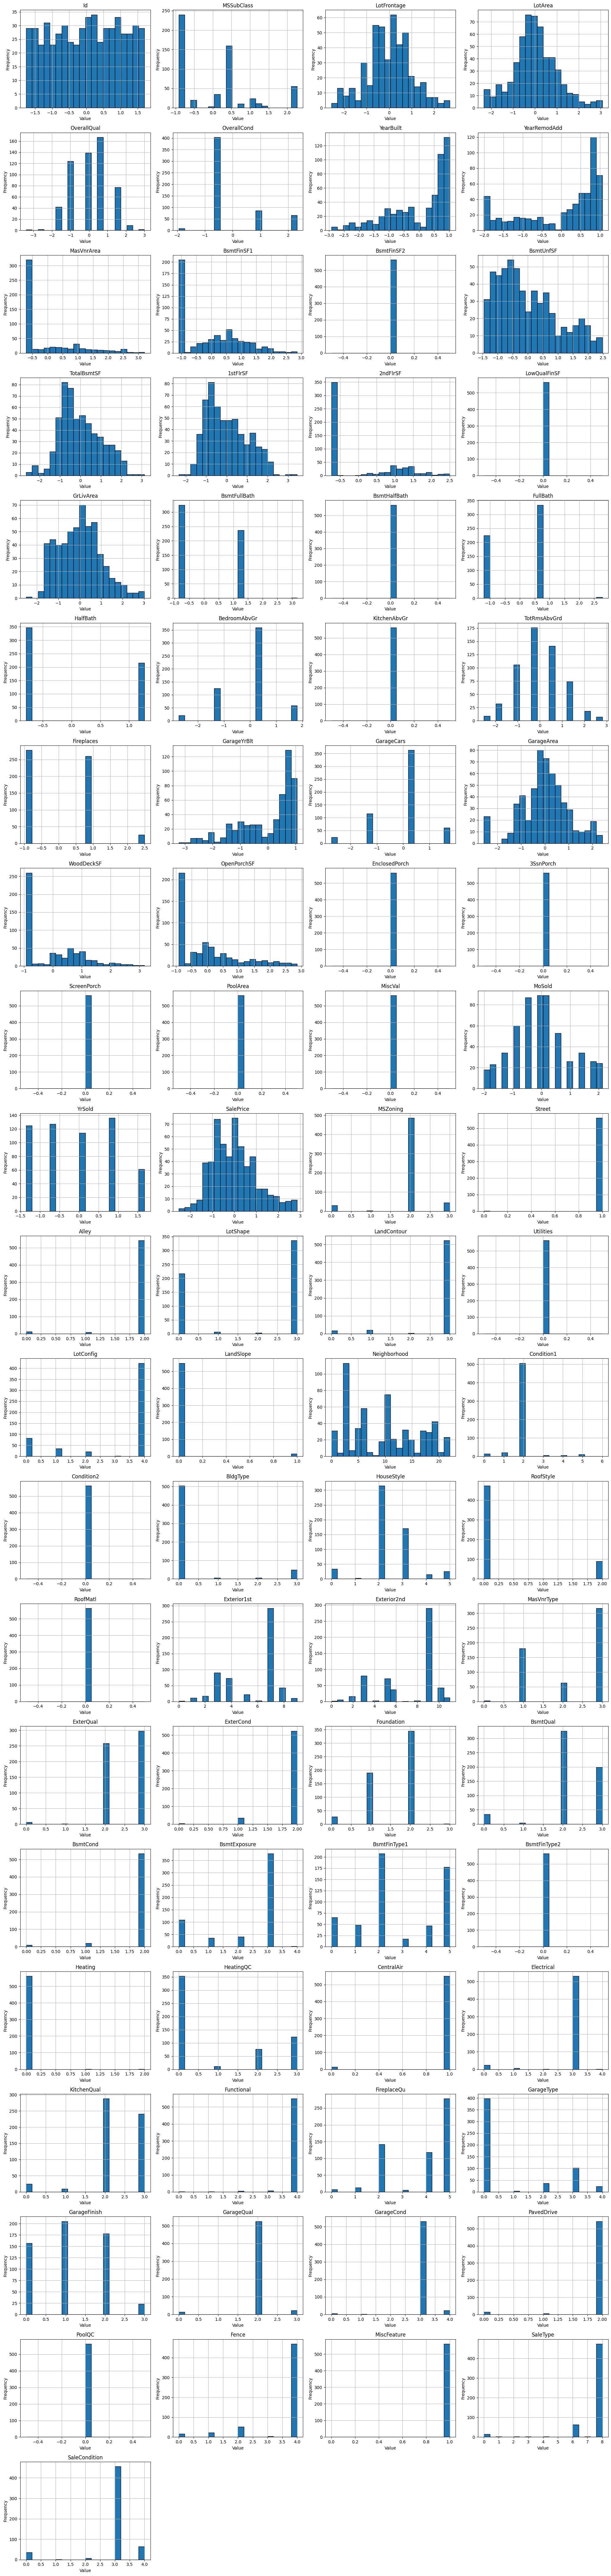

In [24]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]
 
# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4   # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols) # Ceiling division untuk menentukan jumlah baris
 
# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
 
# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()
 
# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')
 
# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
 
# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

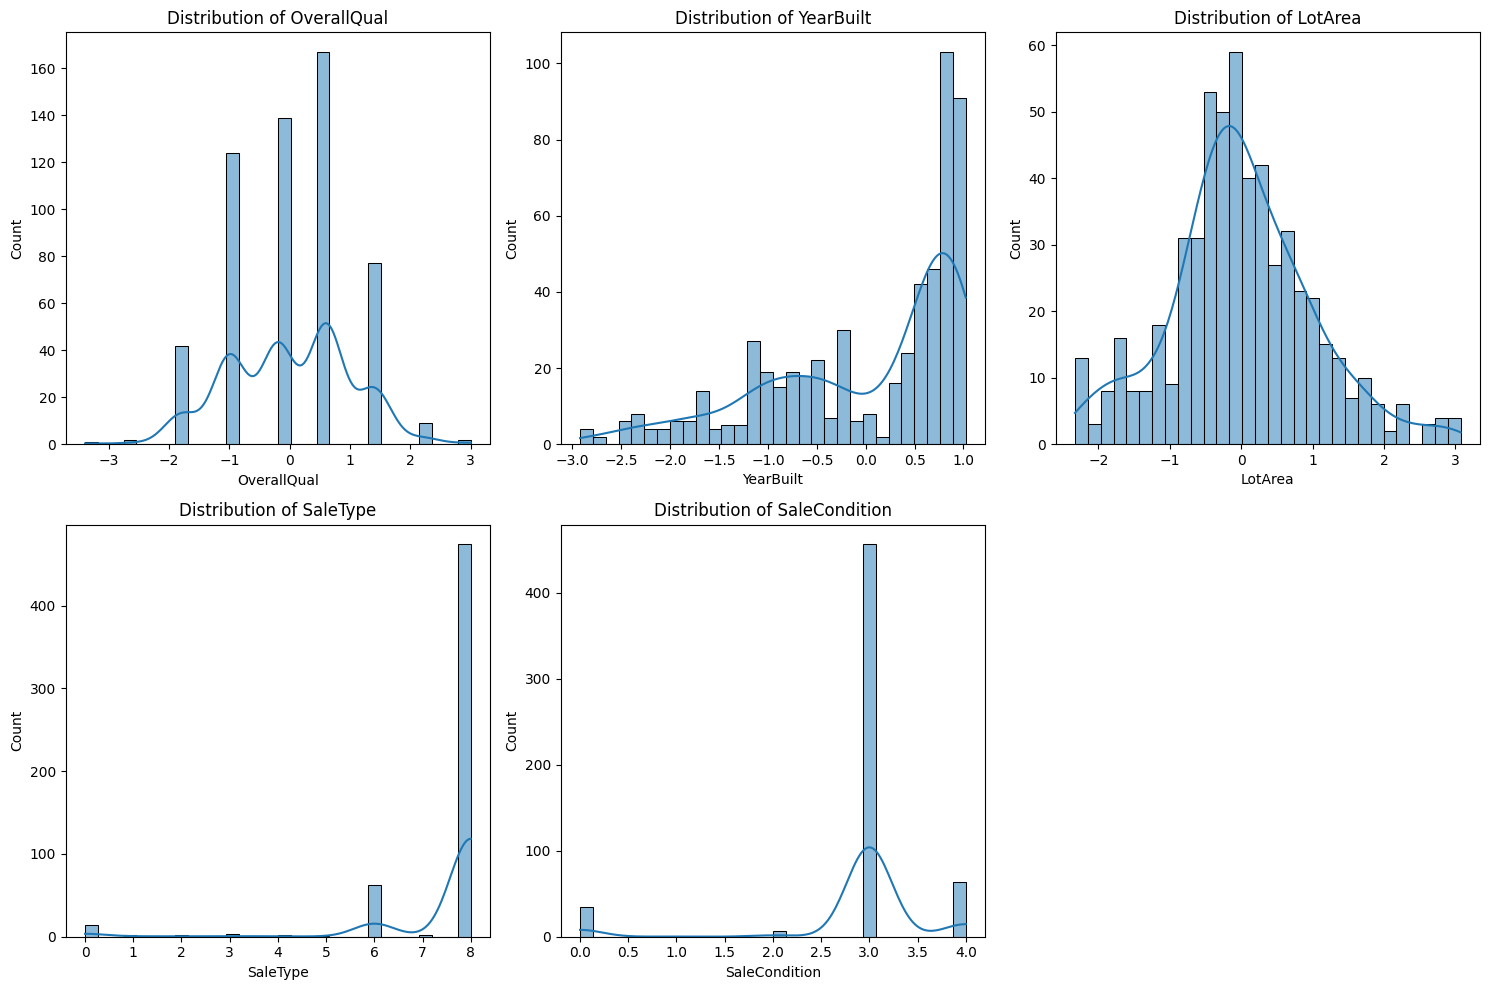

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
 
# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = ['OverallQual', 'YearBuilt', 'LotArea', 'SaleType', 'SaleCondition']
 
plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')
 
plt.tight_layout()
plt.show()

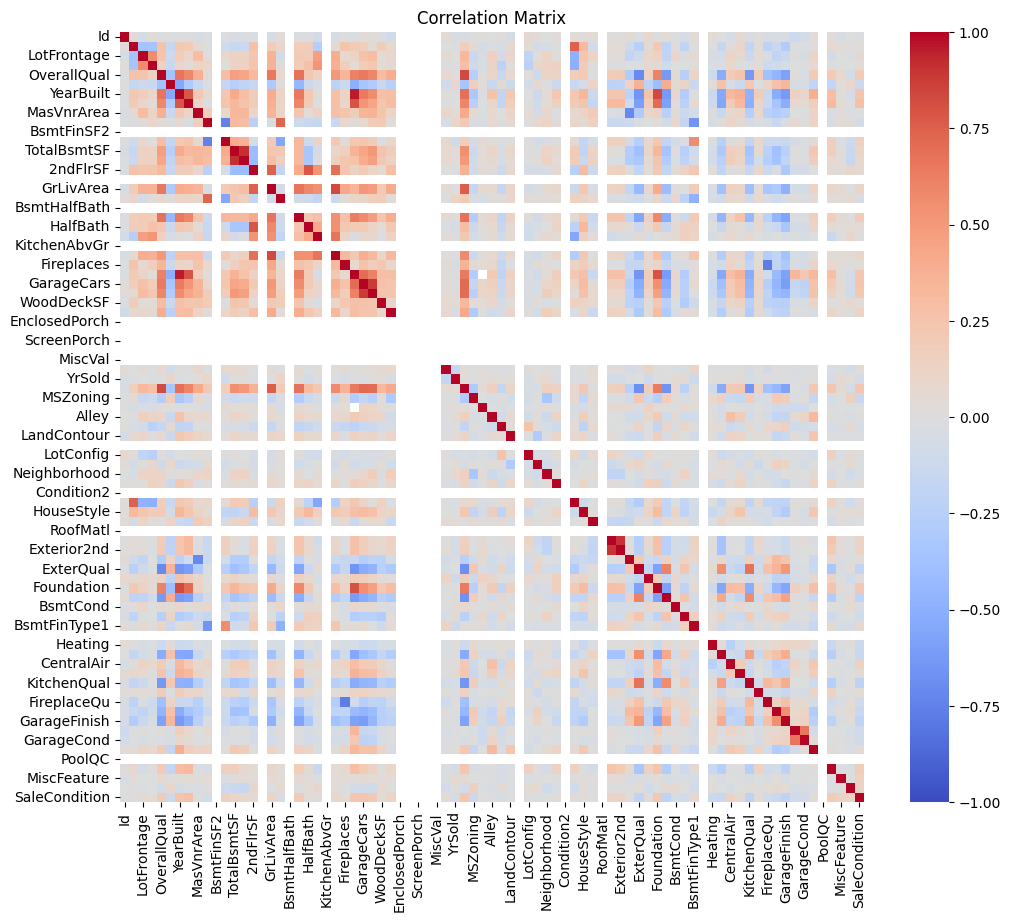

In [26]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()
 
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

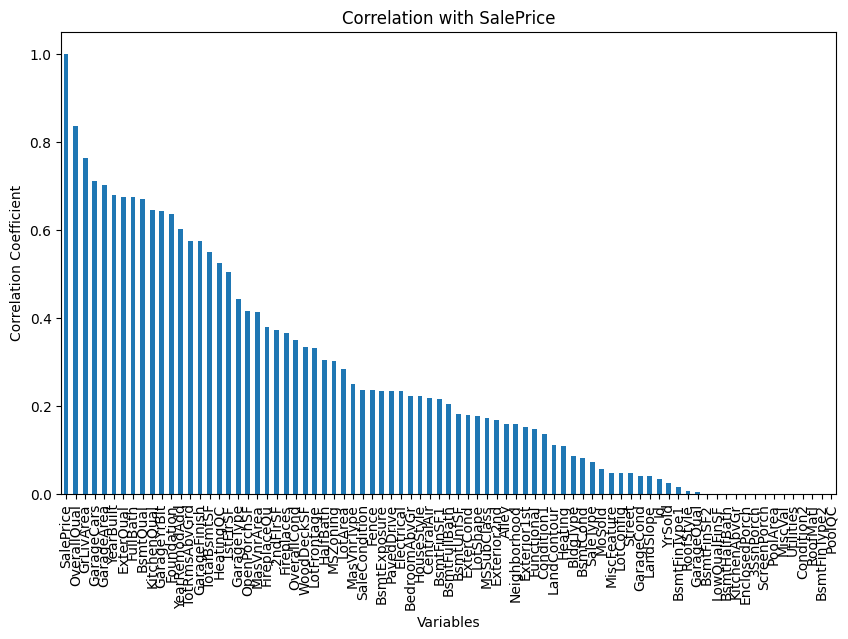

In [27]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['SalePrice']
 
# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)
 
plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with SalePrice')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

In [28]:
import sklearn

In [29]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['SalePrice'])
y = df_lencoder['SalePrice'] 

In [30]:
from sklearn.model_selection import train_test_split
 
# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [31]:
# menghitung panjang/jumlah data 
print("Jumlah data: ",len(X))
# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ",len(x_test))

Jumlah data:  563
Jumlah data latih:  450
Jumlah data test:  113


In [32]:
x_train.isna().sum()
y_train.isna().sum()

np.int64(0)

In [33]:
from sklearn.impute import SimpleImputer
import pandas as pd

imputer = SimpleImputer(strategy="median")
x_train = pd.DataFrame(imputer.fit_transform(x_train), columns=x_train.columns, index=x_train.index)
x_test = pd.DataFrame(imputer.transform(x_test), columns=x_test.columns, index=x_test.index)

In [34]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)
 
# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)
 
# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
 
# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)
 
# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}
 
# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results

,MAE,MSE,R2
Lars,0.794195,1.002299,0.088413


In [36]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)
 
# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results

,MAE,MSE,R2
Lars,0.794195,1.002299,0.088413
Linear Regression,0.256276,0.126542,0.884911


In [37]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)
 
# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.794195,1.002299,0.088413
Linear Regression,0.256276,0.126542,0.884911
GradientBoostingRegressor,0.236389,0.113724,0.896569


In [38]:
import joblib
 
# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model.joblib')

['gbr_model.joblib']

In [39]:
import pickle
 
# Menyimpan model ke dalam file
with open('gbr_model.pkl', 'wb') as file:
    pickle.dump(GBR, file)

In [40]:
# Memuat model dari file joblib
joblib_model = joblib.load('gbr_model.joblib')
 
# Memuat model dari file pickle
with open('gbr_model.pkl', 'rb') as file:
    pickle_model = pickle.load(file)

In [41]:
from flask import Flask, request, jsonify
import joblib
 
# Inisialisasi aplikasi Flask
app = Flask(__name__)
 
# Memuat model yang telah disimpan
joblib_model = joblib.load('gbr_model.joblib') # Pastikan path file sesuai dengan penyimpanan Anda
 
@app.route('/predict', methods=['POST'])
def predict():
    data = request.json['data']  # Mengambil data dari request JSON
    prediction = joblib_model.predict(data) # Melakukan prediksi (harus dalam bentuk 2D array)
    return jsonify({'prediction': prediction.tolist()})
 
if __name__ == '__main__':
    app.run(debug=True)

 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
 * Restarting with stat


SystemExit: 1

C:\Users\Yanti Warti\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\interactiveshell.py:3755: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [7]:
{
    "data": [[ 2.58814198e-02, -9.17637181e-01, 7.98581973e-01,
               4.65818252e-03, -1.90862680e-01, -5.23676539e-01,
               5.44502437e-01, 3.98055532e-01, -7.01765886e-01,
               1.84842886e+00, 0.00000000e+00, -7.99528238e-01,
               1.40061034e+00, 1.30453595e+00, -7.43485947e-01,
               0.00000000e+00, 1.75076143e-01, 1.15778146e+00,
               0.00000000e+00, 7.87362373e-01, -7.89877652e-01,
               2.94736730e-01, 0.00000000e+00, -2.35844028e-01,
               -9.44263321e-01, 4.99353260e-01, 2.73711363e-01,
               5.33168369e-01, 7.90365547e-01, -3.15583095e-01,
               0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
               0.00000000e+00, 0.00000000e+00, 2.51894504e-01,
               -1.35256152e+00, 2.00000000e+00, 1.00000000e+00,
               0.00000000e+00, 3.00000000e+00, 0.00000000e+00,
               4.00000000e+00, 0.00000000e+00, 3.00000000e+00,
               2.00000000e+00, 0.00000000e+00, 0.00000000e+00,
               2.00000000e+00, 0.00000000e+00, 0.00000000e+00,
            7.00000000e+00, 9.00000000e+00, 1.00000000e+00,
               3.00000000e+00, 1.00000000e+00, 2.00000000e+00,
               2.00000000e+00, 2.00000000e+00, 1.00000000e+00,
               2.00000000e+00, 0.00000000e+00, 0.00000000e+00,
               0.00000000e+00, 1.00000000e+00, 2.00000000e+00,
               2.00000000e+00, 4.00000000e+00, 2.00000000e+00,
               0.00000000e+00, 1.00000000e+00, 2.00000000e+00,
               3.00000000e+00, 2.00000000e+00, 8.00000000e+00,
               3.00000000e+00]]
}

{'data': [[0.0258814198,
   -0.917637181,
   0.798581973,
   0.00465818252,
   -0.19086268,
   -0.523676539,
   0.544502437,
   0.398055532,
   -0.701765886,
   1.84842886,
   0.0,
   -0.799528238,
   1.40061034,
   1.30453595,
   -0.743485947,
   0.0,
   0.175076143,
   1.15778146,
   0.0,
   0.787362373,
   -0.789877652,
   0.29473673,
   0.0,
   -0.235844028,
   -0.944263321,
   0.49935326,
   0.273711363,
   0.533168369,
   0.790365547,
   -0.315583095,
   0.0,
   0.0,
   0.0,
   0.0,
   0.0,
   0.251894504,
   -1.35256152,
   2.0,
   1.0,
   0.0,
   3.0,
   0.0,
   4.0,
   0.0,
   3.0,
   2.0,
   0.0,
   0.0,
   2.0,
   0.0,
   0.0,
   7.0,
   9.0,
   1.0,
   3.0,
   1.0,
   2.0,
   2.0,
   2.0,
   1.0,
   2.0,
   0.0,
   0.0,
   0.0,
   1.0,
   2.0,
   2.0,
   4.0,
   2.0,
   0.0,
   1.0,
   2.0,
   3.0,
   2.0,
   8.0,
   3.0]]}